# Relatório unificado — SICOR Cerrado × Cadastros do SICAR Suspensos — versão 2

## Análise sem deduplicação | período de 2021 a 2025

Este notebook preserva todas as linhas da base expandida de interseções. A unidade analítica principal é o **registro original do CSV**, identificado pela coluna auxiliar `_ID_LINHA_ORIGINAL`.

### Regras metodológicas da versão 2

- Nenhum registro é eliminado por repetição de `id_gleba2`, cadastro do SICAR suspenso, `REF_BACEN` ou geometria.
- As contagens principais utilizam todas as linhas ou todas as partes espaciais produzidas pelo corte municipal.
- `nunique()` é empregado somente em indicadores complementares de identificadores distintos; ele não substitui nem reduz a base detalhada.
- A soma financeira considera os valores presentes em todas as linhas e, por isso, é identificada como **soma dos valores das linhas**, e não como valor de operações únicas.
- A união geométrica é mantida apenas como medida complementar de área física coberta. Ela não é usada para eliminar registros.

Todos os resultados são gravados em uma pasta independente chamada `versao_2`.


In [1]:
# ============================================================
# 1. PREPARAR O AMBIENTE
# ============================================================

!pip install -q --upgrade geopandas pyogrio shapely geobr mapclassify python-docx

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from collections import OrderedDict
import inspect
import math
import re
import time
import unicodedata
import warnings
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

from shapely import force_2d, make_valid, normalize as shapely_normalize
from shapely import wkt as shapely_wkt
from shapely.geometry import GeometryCollection, MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry
from shapely.ops import unary_union

import geobr

from docx import Document
from docx.enum.section import WD_ORIENT
from docx.enum.table import WD_CELL_VERTICAL_ALIGNMENT, WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.style import WD_STYLE_TYPE
from docx.enum.section import WD_SECTION
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Inches, Pt, RGBColor

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", None)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

print("Ambiente preparado.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.7/341.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 479.0/479.0 kB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 136.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 133.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
Mounted at /conten

In [2]:
# ============================================================
# 2. CAMINHOS, PARÂMETROS E PASTA DE SAÍDA
# ============================================================

# Caminho da base de interseção expandida por id_gleba2.

ARQUIVO_ENTRADA = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/intersecao_sicor_sicar_suspensos_expandida_por_id_gleba2.csv')

PASTA_SAIDA = ARQUIVO_ENTRADA.parent / "versao_2"
PASTA_MAPAS = PASTA_SAIDA / "mapas"
PASTA_GRAFICOS = PASTA_SAIDA / "graficos_histogramas"
PASTA_TABELAS = PASTA_SAIDA / "tabelas"
PASTA_BASES = PASTA_SAIDA / "bases_analiticas"

for pasta in [PASTA_SAIDA, PASTA_MAPAS, PASTA_GRAFICOS, PASTA_TABELAS, PASTA_BASES]:
    pasta.mkdir(parents=True, exist_ok=True)

ARQUIVO_WORD = PASTA_SAIDA / "relatorio_unificado_sicor_sicar_suspensos_2021_2025_versao_2.docx"

TITULO_IMPEDIMENTO = 'Cadastros do SICAR Suspensos'
UNIDADE_SINGULAR = 'cadastro do SICAR suspenso'
UNIDADE_PLURAL = 'cadastros do SICAR suspensos'
ROTULO_UNIDADE = 'Cadastro do SICAR'
ROTULO_TIPOLOGIA_1 = 'Situação cadastral'
ROTULO_TIPOLOGIA_2 = 'Tipo de imóvel'
ROTULO_TIPOLOGIA_3 = 'Condição cadastral complementar'
CAUTELA_ESPECIFICA = 'A análise posterior deve considerar a situação do cadastro na data da operação, o motivo e a vigência da suspensão, a correspondência entre o imóvel financiado e o cadastro ambiental e as exceções normativas aplicáveis.'

CANDIDATOS_ID_UNIDADE = ['SICAR_ID_INTERNO', 'SICAR_ID', 'ID_SICAR', 'COD_IMOVEL', 'COD_IMOVEL_RURAL', 'CAR_ID', 'NUMERO_CAR']
CANDIDATOS_NOME_UNIDADE = ['SICAR_COD_IMOVEL', 'COD_IMOVEL', 'COD_IMOVEL_RURAL', 'NUMERO_CAR', 'CAR', 'NOME_IMOVEL', 'NOME']
CANDIDATOS_TIPOLOGIA_1 = ['SICAR_STATUS', 'SICAR_SITUACAO', 'IND_STATUS', 'STATUS_CADASTRO', 'SITUACAO_CADASTRO', 'SITUACAO', 'STATUS']
CANDIDATOS_TIPOLOGIA_2 = ['SICAR_TIPO_IMOVEL', 'TIPO_IMOVEL', 'TIPO_PROPRIEDADE', 'CATEGORIA_IMOVEL', 'TIPO']
CANDIDATOS_TIPOLOGIA_3 = ['SICAR_CONDICAO', 'CONDICAO_CADASTRO', 'MOTIVO_SUSPENSAO', 'MOTIVO', 'CONDICAO']
CANDIDATOS_UF_UNIDADE = ['SICAR_UF', 'UF_IMOVEL', 'UF_CAR', 'SIGLA_UF', 'SG_UF', 'UF']
CANDIDATOS_AREA_TOTAL_UNIDADE = ['SICAR_AREA_TOTAL_HA', 'AREA_IMOVEL_HA', 'AREA_CAR_HA', 'AREA_TOTAL_HA', 'AREA_HA']

# Se os downloads do geobr não funcionarem, informe arquivos locais abaixo.
ARQUIVO_CERRADO_LOCAL = None
ARQUIVO_ESTADOS_LOCAL = None
ARQUIVO_MUNICIPIOS_LOCAL = None

CRS_ENTRADA = "EPSG:4326"
CRS_GEOGRAFICO = "EPSG:4674"
CRS_AREA = "EPSG:5880"  # SIRGAS 2000 / Brazil Polyconic

TOP_N = 20
TOP_MAPA = 10
MAX_LINHAS_WORD = 30

if not ARQUIVO_ENTRADA.exists():
    raise FileNotFoundError(f"Arquivo de entrada não encontrado: {ARQUIVO_ENTRADA}")

print("Entrada:", ARQUIVO_ENTRADA)
print("Tamanho:", f"{ARQUIVO_ENTRADA.stat().st_size / (1024**2):,.2f} MB")
print("Saída:", PASTA_SAIDA)


Entrada: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/intersecao_sicor_sicar_suspensos_expandida_por_id_gleba2.csv
Tamanho: 1.48 MB
Saída: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/versao_2


In [3]:
# ============================================================
# 3. FUNÇÕES DE LEITURA, NORMALIZAÇÃO E CONVERSÃO
# ============================================================

CODIFICACOES = ["utf-8-sig", "utf-8", "latin-1", "cp1252"]
SEPARADORES = [";", ",", "\t", "|"]


def remover_acentos(texto):
    return "".join(
        caractere
        for caractere in unicodedata.normalize("NFKD", str(texto))
        if not unicodedata.combining(caractere)
    )


def normalizar_nome_coluna(nome):
    nome = remover_acentos(nome).upper().strip().replace("#", "")
    nome = re.sub(r"[^A-Z0-9]+", "_", nome)
    return re.sub(r"_+", "_", nome).strip("_")


def tornar_nomes_unicos(nomes):
    contadores = {}
    saida = []
    for nome in nomes:
        numero = contadores.get(nome, 0)
        saida.append(nome if numero == 0 else f"{nome}_{numero + 1}")
        contadores[nome] = numero + 1
    return saida


def normalizar_colunas(df):
    df = df.copy()
    df.columns = tornar_nomes_unicos([normalizar_nome_coluna(c) for c in df.columns])
    return df


def detectar_csv(caminho):
    ultimo_erro = None
    for encoding in CODIFICACOES:
        for separador in SEPARADORES:
            try:
                teste = pd.read_csv(
                    caminho, sep=separador, encoding=encoding,
                    nrows=10, dtype=object, low_memory=False,
                )
                if teste.shape[1] > 1:
                    return encoding, separador
            except Exception as erro:
                ultimo_erro = erro
    raise RuntimeError(f"Não foi possível interpretar o CSV. Último erro: {ultimo_erro}")


def localizar_coluna(df_ou_colunas, candidatos, obrigatoria=False):
    colunas = list(df_ou_colunas.columns) if hasattr(df_ou_colunas, "columns") else list(df_ou_colunas)
    candidatos = [normalizar_nome_coluna(c) for c in candidatos]
    for candidato in candidatos:
        if candidato in colunas:
            return candidato
    for coluna in colunas:
        for candidato in candidatos:
            if candidato in coluna or coluna in candidato:
                return coluna
    if obrigatoria:
        raise KeyError(f"Nenhuma coluna encontrada para: {candidatos}")
    return None


def localizar_por_termos(df, positivos, negativos=None, prefixos=None):
    positivos = [normalizar_nome_coluna(x) for x in positivos]
    negativos = [normalizar_nome_coluna(x) for x in (negativos or [])]
    prefixos = [normalizar_nome_coluna(x) for x in (prefixos or [])]
    candidatas = []
    for coluna in df.columns:
        if prefixos and not any(coluna.startswith(p) for p in prefixos):
            continue
        if any(n in coluna for n in negativos):
            continue
        pontos = sum(p in coluna for p in positivos)
        if pontos:
            candidatas.append((pontos, -len(coluna), coluna))
    return max(candidatas)[2] if candidatas else None


def texto_limpo(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA, "NULL": pd.NA})
    )


def numero_robusto(serie):
    serie = texto_limpo(serie)
    def converter(valor):
        if pd.isna(valor):
            return np.nan
        texto = str(valor).replace("R$", "").replace("%", "").replace(" ", "").strip()
        if "," in texto and "." in texto:
            texto = texto.replace(".", "").replace(",", ".") if texto.rfind(",") > texto.rfind(".") else texto.replace(",", "")
        elif "," in texto:
            texto = texto.replace(".", "").replace(",", ".")
        try:
            return float(texto)
        except Exception:
            return np.nan
    return serie.map(converter).astype(float)


def primeiro_nao_nulo(serie):
    valores = serie.dropna()
    return pd.NA if valores.empty else valores.iloc[0]


def unir_distintos(serie, limite=50):
    valores = sorted(set(serie.dropna().astype(str).str.strip()) - {""})
    if len(valores) > limite:
        valores = valores[:limite] + [f"... +{len(valores)-limite} valores"]
    return " | ".join(valores) if valores else pd.NA


def corrigir_geometria_poligonal(geometria):
    if geometria is None:
        return None
    try:
        if geometria.is_empty:
            return None
        geometria = force_2d(geometria)
        if not geometria.is_valid:
            geometria = make_valid(geometria)
    except Exception:
        try:
            geometria = geometria.buffer(0)
        except Exception:
            return None
    if isinstance(geometria, (Polygon, MultiPolygon)):
        try:
            return shapely_normalize(geometria)
        except Exception:
            return geometria
    if isinstance(geometria, GeometryCollection):
        partes = [g for g in geometria.geoms if isinstance(g, (Polygon, MultiPolygon)) and not g.is_empty]
        return corrigir_geometria_poligonal(unary_union(partes)) if partes else None
    return None


def converter_wkt(valor):
    if valor is None:
        return None
    try:
        if bool(pd.isna(valor)):
            return None
    except Exception:
        pass
    if isinstance(valor, BaseGeometry):
        return corrigir_geometria_poligonal(valor)
    if isinstance(valor, (bytes, bytearray, memoryview)):
        try:
            texto = bytes(valor).decode("utf-8")
        except UnicodeDecodeError:
            texto = bytes(valor).decode("latin-1", errors="ignore")
    else:
        texto = str(valor)
    texto = texto.strip().strip('"').strip("'")
    if not texto or texto.upper() in {"NAN", "NONE", "NULL", "<NA>"}:
        return None
    if texto.upper().startswith("SRID=") and ";" in texto:
        texto = texto.split(";", 1)[1]
    try:
        return corrigir_geometria_poligonal(shapely_wkt.loads(texto))
    except Exception:
        return None


def unir_geometrias_unicas(serie, crs=CRS_AREA):
    geometrias = [g for g in serie if g is not None and not g.is_empty]
    if not geometrias:
        return None
    try:
        return gpd.GeoSeries(geometrias, crs=crs).union_all()
    except (AttributeError, TypeError):
        return unary_union(geometrias)


def normalizar_gdf(gdf):
    crs = gdf.crs
    geometria_original = gdf.geometry.name
    mapa = dict(zip(gdf.columns, tornar_nomes_unicos([normalizar_nome_coluna(c) for c in gdf.columns])))
    gdf = gdf.rename(columns=mapa)
    gdf = gpd.GeoDataFrame(gdf, geometry=mapa[geometria_original], crs=crs)
    return gdf.rename_geometry("geometry") if gdf.geometry.name != "geometry" else gdf


print("Funções carregadas.")

Funções carregadas.


In [4]:
# ============================================================
# 4. LER A BASE E IDENTIFICAR AUTOMATICAMENTE OS CAMPOS
# ============================================================

encoding, separador = detectar_csv(ARQUIVO_ENTRADA)
dados_brutos = pd.read_csv(
    ARQUIVO_ENTRADA, sep=separador, encoding=encoding,
    dtype=object, low_memory=False,
)
dados_brutos = normalizar_colunas(dados_brutos)

COLUNA_ID_GLEBA = localizar_coluna(dados_brutos, ["ID_GLEBA2", "ID_GLEBA_2"], obrigatoria=True)
COLUNA_REF = localizar_coluna(dados_brutos, ["REF_BACEN", "CD_REF_BACEN"], obrigatoria=False)
COLUNA_ANO = localizar_coluna(
    dados_brutos,
    ["ANO", "ANO_BASE", "ANO_OPERACAO", "ANO_COPIA_BASE", "PRIMEIRO_ANO_OPERACAO", "ANO_REFERENCIA"],
    obrigatoria=False,
)
COLUNA_VALOR = localizar_coluna(
    dados_brutos,
    ["VALOR_TOTAL_CREDITO_R", "VALOR_CREDITO", "VALOR_FINANCIADO_R", "VL_PARC_CREDITO", "CREDITO_TOTAL"],
    obrigatoria=False,
)
COLUNA_TIPO_PRODUTOR = localizar_coluna(
    dados_brutos,
    ["TIPO_PRODUTOR_ANALISE", "TIPO_PRODUTOR_PORTE", "DESC_CATEG_EMITENTE", "CATEGORIA_EMITENTE", "PORTE_PRODUTOR"],
    obrigatoria=False,
)
COLUNA_PROGRAMA = localizar_coluna(dados_brutos, ["DESC_PROGRAMA", "GRUPO_PROGRAMA_CREDITO", "PROGRAMA", "CD_PROGRAMA"], obrigatoria=False)

COLUNA_UNIDADE_ID = localizar_coluna(dados_brutos, CANDIDATOS_ID_UNIDADE, obrigatoria=True)
COLUNA_UNIDADE_NOME = localizar_coluna(dados_brutos, CANDIDATOS_NOME_UNIDADE, obrigatoria=False)
COLUNA_TIPOLOGIA_1 = localizar_coluna(dados_brutos, CANDIDATOS_TIPOLOGIA_1, obrigatoria=False)
COLUNA_TIPOLOGIA_2 = localizar_coluna(dados_brutos, CANDIDATOS_TIPOLOGIA_2, obrigatoria=False)
COLUNA_TIPOLOGIA_3 = localizar_coluna(dados_brutos, CANDIDATOS_TIPOLOGIA_3, obrigatoria=False)
COLUNA_UF_UNIDADE = localizar_coluna(dados_brutos, CANDIDATOS_UF_UNIDADE, obrigatoria=False)
COLUNA_AREA_TOTAL_UNIDADE = localizar_coluna(dados_brutos, CANDIDATOS_AREA_TOTAL_UNIDADE, obrigatoria=False)

COLUNA_AREA_INTERSECAO = localizar_coluna(dados_brutos, ["AREA_INTERSECAO_HA", "AREA_SOBREPOSICAO_HA"], obrigatoria=False)
COLUNA_PERCENTUAL = localizar_coluna(dados_brutos, ["PERCENTUAL_GLEBA_INTERSECTADA", "PERCENTUAL_INTERSECAO", "PERC_INTERSECAO"], obrigatoria=False)
COLUNA_AREA_GLEBA = localizar_coluna(dados_brutos, ["AREA_GLEBA_HA_CALCULADA", "AREA_GLEBA_HA"], obrigatoria=False)
COLUNA_GEOM_INTERSECAO = localizar_coluna(
    dados_brutos,
    ["GEOMETRIA_INTERSECAO_WKT", "INTERSECAO_WKT", "GEOMETRIA_SOBREPOSICAO_WKT", "WKT_INTERSECAO"],
    obrigatoria=False,
)
COLUNA_GEOM_GLEBA = localizar_coluna(
    dados_brutos,
    ["GT_GEOMETRIA_REPRESENTATIVA", "GT_GEOMETRIA", "GEOMETRIA_GLEBA_WKT", "GEOMETRIA_GLEBA", "WKT_GLEBA"],
    obrigatoria=False,
)

campos_identificados = pd.DataFrame({
    "CAMPO_ANALITICO": [
        "id_gleba2", "REF_BACEN", "Ano", "Valor do crédito", "Tipo de produtor", "Programa",
        f"ID: {ROTULO_UNIDADE}", f"Nome: {ROTULO_UNIDADE}", ROTULO_TIPOLOGIA_1,
        ROTULO_TIPOLOGIA_2, ROTULO_TIPOLOGIA_3, f"UF: {ROTULO_UNIDADE}",
        f"Área total: {ROTULO_UNIDADE}", "Área da interseção", "% da gleba",
        "Área da gleba", "Geometria da interseção", "Geometria da gleba",
    ],
    "COLUNA_ENCONTRADA": [
        COLUNA_ID_GLEBA, COLUNA_REF, COLUNA_ANO, COLUNA_VALOR, COLUNA_TIPO_PRODUTOR, COLUNA_PROGRAMA,
        COLUNA_UNIDADE_ID, COLUNA_UNIDADE_NOME, COLUNA_TIPOLOGIA_1, COLUNA_TIPOLOGIA_2,
        COLUNA_TIPOLOGIA_3, COLUNA_UF_UNIDADE, COLUNA_AREA_TOTAL_UNIDADE,
        COLUNA_AREA_INTERSECAO, COLUNA_PERCENTUAL, COLUNA_AREA_GLEBA,
        COLUNA_GEOM_INTERSECAO, COLUNA_GEOM_GLEBA,
    ],
})

print(f"Arquivo lido: {len(dados_brutos):,} linhas × {dados_brutos.shape[1]:,} colunas")
print("Codificação:", encoding, "| Separador:", repr(separador))
display(campos_identificados)


Arquivo lido: 530 linhas × 50 colunas
Codificação: utf-8-sig | Separador: ';'


,CAMPO_ANALITICO,COLUNA_ENCONTRADA
0,id_gleba2,ID_GLEBA2
1,REF_BACEN,REF_BACEN
2,Ano,ANO_BASE
3,Valor do crédito,VL_PARC_CREDITO
4,Tipo de produtor,TIPO_PRODUTOR_ANALISE
5,Programa,DESC_PROGRAMA
6,ID: Cadastro do SICAR,CAR_COD_IMOVEL
7,Nome: Cadastro do SICAR,CAR_COD_IMOVEL
8,Situação cadastral,CAR_STATUS_IMO
9,Tipo de imóvel,TIPO_PRODUTOR_ANALISE


In [5]:
# ============================================================
# 5. PREPARAR DIMENSÕES, PERÍODO E CLASSIFICAÇÕES
# ============================================================

dados = dados_brutos.copy().reset_index(drop=True)
dados["_ID_LINHA_ORIGINAL"] = np.arange(len(dados), dtype=np.int64)
dados["_ID_GLEBA2"] = texto_limpo(dados[COLUNA_ID_GLEBA])
dados["_UNIDADE_ID"] = texto_limpo(dados[COLUNA_UNIDADE_ID])
dados["_REF_BACEN"] = texto_limpo(dados[COLUNA_REF]) if COLUNA_REF else pd.Series(pd.NA, index=dados.index, dtype="string")

dados["_ANO"] = (
    pd.to_numeric(texto_limpo(dados[COLUNA_ANO]), errors="coerce").astype("Int64")
    if COLUNA_ANO else pd.Series(pd.NA, index=dados.index, dtype="Int64")
)
dados.loc[~dados["_ANO"].between(2000, 2100, inclusive="both"), "_ANO"] = pd.NA

dados["_VALOR_R"] = numero_robusto(dados[COLUNA_VALOR]) if COLUNA_VALOR else np.nan
dados["_AREA_INTERSECAO_CSV_HA"] = numero_robusto(dados[COLUNA_AREA_INTERSECAO]) if COLUNA_AREA_INTERSECAO else np.nan
dados["_PERCENTUAL_GLEBA"] = numero_robusto(dados[COLUNA_PERCENTUAL]) if COLUNA_PERCENTUAL else np.nan
dados["_AREA_GLEBA_CSV_HA"] = numero_robusto(dados[COLUNA_AREA_GLEBA]) if COLUNA_AREA_GLEBA else np.nan
dados["_AREA_TOTAL_UNIDADE_HA"] = numero_robusto(dados[COLUNA_AREA_TOTAL_UNIDADE]) if COLUNA_AREA_TOTAL_UNIDADE else np.nan

dados["_UNIDADE_NOME"] = texto_limpo(dados[COLUNA_UNIDADE_NOME]) if COLUNA_UNIDADE_NOME else pd.Series(pd.NA, index=dados.index, dtype="string")
dados["_UNIDADE_NOME"] = dados["_UNIDADE_NOME"].fillna("Cadastro do SICAR sem nome - ID " + dados["_UNIDADE_ID"].astype(str))
dados["_TIPOLOGIA_1"] = texto_limpo(dados[COLUNA_TIPOLOGIA_1]).fillna("Não informado") if COLUNA_TIPOLOGIA_1 else "Não informado"
dados["_TIPOLOGIA_2"] = texto_limpo(dados[COLUNA_TIPOLOGIA_2]).fillna("Não informado") if COLUNA_TIPOLOGIA_2 else "Não informado"
dados["_TIPOLOGIA_3"] = texto_limpo(dados[COLUNA_TIPOLOGIA_3]).fillna("Não informado") if COLUNA_TIPOLOGIA_3 else "Não informado"
dados["_UF_UNIDADE"] = texto_limpo(dados[COLUNA_UF_UNIDADE]).fillna("Não informado") if COLUNA_UF_UNIDADE else "Não informado"
dados["_PROGRAMA"] = texto_limpo(dados[COLUNA_PROGRAMA]).fillna("Não informado") if COLUNA_PROGRAMA else "Não informado"

texto_tipo = texto_limpo(dados[COLUNA_TIPO_PRODUTOR]).fillna("") if COLUNA_TIPO_PRODUTOR else pd.Series("", index=dados.index)
texto_classificacao = (
    texto_tipo.astype(str) + " | " + dados["_PROGRAMA"].astype(str)
).map(remover_acentos).str.upper()

condicao_pronaf = texto_classificacao.str.contains(r"PRONAF|PEQUEN|GRUPO\s*B", regex=True, na=False)
condicao_pronamp = texto_classificacao.str.contains(r"PRONAMP|MEDIO", regex=True, na=False)
dados["_TIPO_PRODUTOR"] = np.select(
    [condicao_pronaf, condicao_pronamp],
    ["Pronaf / pequeno produtor", "Pronamp / médio produtor"],
    default="Demais produtores",
)

mascara_chaves_validas = dados["_ID_GLEBA2"].notna() & dados["_UNIDADE_ID"].notna()
linhas_sem_chaves = int((~mascara_chaves_validas).sum())

anos_validos = sorted(dados["_ANO"].dropna().astype(int).unique().tolist())
if anos_validos:
    ANO_INICIAL, ANO_FINAL = min(anos_validos), max(anos_validos)
    PERIODO = str(ANO_INICIAL) if ANO_INICIAL == ANO_FINAL else f"{ANO_INICIAL} a {ANO_FINAL}"
    PERIODO_CURTO = str(ANO_INICIAL) if ANO_INICIAL == ANO_FINAL else f"{ANO_INICIAL}–{ANO_FINAL}"
else:
    ANO_INICIAL, ANO_FINAL = None, None
    PERIODO = "período não identificado na base"
    PERIODO_CURTO = "período não identificado"

if not anos_validos:
    raise ValueError(
        "Não foi possível identificar o período. Acrescente o nome correto da coluna anual aos candidatos de COLUNA_ANO."
    )

print("Período identificado:", PERIODO)
print("Linhas originais preservadas:", f"{len(dados):,}")
print(f"Linhas sem id_gleba2 ou {UNIDADE_SINGULAR}:", f"{linhas_sem_chaves:,}")
assert len(dados) == len(dados_brutos)
assert dados["_ID_LINHA_ORIGINAL"].is_unique


Período identificado: 2021 a 2025
Linhas originais preservadas: 530
Linhas sem id_gleba2 ou cadastro do SICAR suspenso: 0


In [6]:
# ============================================================
# 6. CONVERTER GEOMETRIAS E PRESERVAR TODOS OS REGISTROS
# ============================================================

if COLUNA_GEOM_INTERSECAO is None:
    raise KeyError(
        "A base precisa conter a geometria WKT da interseção para produzir os mapas. "
        "Acrescente o nome correto da coluna aos candidatos de COLUNA_GEOM_INTERSECAO."
    )

# A base principal 'dados' permanece completa. A seleção abaixo é apenas
# uma base operacional para cálculos que exigem identificadores espaciais.
dados_espaciais = dados.loc[mascara_chaves_validas].copy()

geometrias_intersecao = [
    converter_wkt(valor)
    for valor in dados_espaciais[COLUNA_GEOM_INTERSECAO].astype(object).tolist()
]

gdf = gpd.GeoDataFrame(
    dados_espaciais.copy(),
    geometry=gpd.GeoSeries(
        geometrias_intersecao,
        index=dados_espaciais.index,
        crs=CRS_ENTRADA,
    ),
    crs=CRS_ENTRADA,
)

# Linhas com geometria ausente continuam em 'dados', mas não podem
# participar das operações geométricas.
gdf = gdf.loc[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
gdf_area = gdf.to_crs(CRS_AREA)
gdf["_AREA_INTERSECAO_GEOM_HA"] = (gdf_area.geometry.area / 10_000).to_numpy()

linhas_geometricas_validas = len(gdf)

# Todas as linhas com geometria válida são preservadas.
gdf_ocorrencias = gdf.reset_index(drop=True).copy()

# Geometria integral da gleba: todas as linhas são mantidas.
if COLUNA_GEOM_GLEBA:
    candidatos_gleba = dados_espaciais.copy()
    geom_glebas = [
        converter_wkt(valor)
        for valor in candidatos_gleba[COLUNA_GEOM_GLEBA].astype(object).tolist()
    ]
    gdf_glebas = gpd.GeoDataFrame(
        candidatos_gleba.copy(),
        geometry=gpd.GeoSeries(
            geom_glebas,
            index=candidatos_gleba.index,
            crs=CRS_ENTRADA,
        ),
        crs=CRS_ENTRADA,
    )
    gdf_glebas = gdf_glebas.loc[
        gdf_glebas.geometry.notna() & ~gdf_glebas.geometry.is_empty
    ].copy()
    gdf_glebas["_AREA_GLEBA_GEOM_HA"] = (
        gdf_glebas.to_crs(CRS_AREA).geometry.area / 10_000
    ).to_numpy()
else:
    gdf_glebas = gdf_ocorrencias.copy()
    gdf_glebas["_AREA_GLEBA_GEOM_HA"] = gdf_glebas["_AREA_GLEBA_CSV_HA"]

# Base financeira com todas as linhas que possuem REF_BACEN.
# Não há seleção de uma linha representativa por operação.
if COLUNA_REF:
    base_operacoes = dados.loc[dados["_REF_BACEN"].notna()].copy()
else:
    base_operacoes = pd.DataFrame(columns=dados.columns)

print("Linhas originais:", f"{len(dados):,}")
print("Linhas com chaves espaciais válidas:", f"{len(dados_espaciais):,}")
print("Geometrias de interseção válidas:", f"{linhas_geometricas_validas:,}")
print("Registros espaciais preservados:", f"{len(gdf_ocorrencias):,}")
print("Registros financeiros preservados:", f"{len(base_operacoes):,}")

assert len(gdf_ocorrencias) == linhas_geometricas_validas
assert gdf_ocorrencias["_ID_LINHA_ORIGINAL"].is_unique


Linhas originais: 530
Linhas com chaves espaciais válidas: 530
Geometrias de interseção válidas: 530
Registros espaciais preservados: 530
Registros financeiros preservados: 530


In [7]:
# ============================================================
# 7. CARREGAR CERRADO, ESTADOS E MUNICÍPIOS
# ============================================================

def carregar_vetor(caminho_local, funcao_geobr, rotulo, *args, **kwargs):
    """
    Lê uma malha local ou tenta baixá-la novamente pelo geobr.

    cache=False evita reutilizar um arquivo temporário corrompido. O parâmetro
    só é acrescentado quando existe na versão instalada da função do geobr.
    """
    if caminho_local:
        caminho = Path(caminho_local)
        if not caminho.exists():
            raise FileNotFoundError(f"Arquivo vetorial local não encontrado: {caminho}")
        print(f"Lendo {rotulo} do arquivo local: {caminho}")
        return gpd.read_file(caminho)

    parametros = inspect.signature(funcao_geobr).parameters
    argumentos = dict(kwargs)

    if "cache" in parametros:
        argumentos["cache"] = False

    if "show_progress" in parametros:
        argumentos["show_progress"] = True

    ultimo_erro = None

    for tentativa in range(1, 4):
        try:
            print(f"Baixando {rotulo} pelo geobr — tentativa {tentativa}/3...")
            camada = funcao_geobr(*args, **argumentos)

            if camada is None or camada.empty:
                raise RuntimeError(f"O geobr retornou a malha de {rotulo} vazia.")

            print(f"{rotulo.capitalize()} carregado: {len(camada):,} feições.")
            return camada

        except (ConnectionError, OSError, RuntimeError) as erro:
            ultimo_erro = erro
            print(f"Falha na tentativa {tentativa}: {erro}")

            if tentativa < 3:
                time.sleep(2 * tentativa)

    raise ConnectionError(
        f"Não foi possível baixar {rotulo} após três tentativas. "
        "A conexão do Colab com o servidor do geobr pode estar instável. "
        "Baixe essa malha, salve-a no Google Drive e informe seu caminho "
        "na variável local correspondente da célula 2. "
        f"Último erro: {ultimo_erro}"
    )


biomas = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_CERRADO_LOCAL,
        geobr.read_biomes,
        "biomas",
        year=2019,
        simplified=True,
    )
)
coluna_bioma = localizar_coluna(biomas, ["NAME_BIOME", "NOME_BIOMA", "BIOME", "BIOMA", "NAME"], obrigatoria=True)
cerrado = biomas[
    biomas[coluna_bioma].astype(str).map(remover_acentos).str.upper().str.contains("CERRADO", na=False)
].copy()
cerrado = cerrado.set_crs(CRS_GEOGRAFICO, allow_override=True) if cerrado.crs is None else cerrado.to_crs(CRS_GEOGRAFICO)

estados = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_ESTADOS_LOCAL,
        geobr.read_state,
        "estados",
        year=2020,
        simplified=True,
    )
)
coluna_uf_estado = localizar_coluna(estados, ["ABBREV_STATE", "SIGLA_UF", "SG_UF", "UF"], obrigatoria=True)
estados["UF"] = texto_limpo(estados[coluna_uf_estado]).str.upper()
estados = estados.set_crs(CRS_GEOGRAFICO, allow_override=True) if estados.crs is None else estados.to_crs(CRS_GEOGRAFICO)

municipios = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_MUNICIPIOS_LOCAL,
        geobr.read_municipality,
        "municípios",
        code_muni="all",
        year=2020,
        simplified=True,
    )
)
coluna_codigo_muni = localizar_coluna(municipios, ["CODE_MUNI", "COD_MUN", "CD_MUN", "CODIGO_MUNICIPIO"], obrigatoria=True)
coluna_nome_muni = localizar_coluna(municipios, ["NAME_MUNI", "NOME_MUNICIPIO", "NM_MUN", "MUNICIPIO"], obrigatoria=True)
coluna_uf_muni = localizar_coluna(municipios, ["ABBREV_STATE", "SIGLA_UF", "SG_UF", "UF"], obrigatoria=True)
municipios["COD_MUNICIPIO"] = texto_limpo(municipios[coluna_codigo_muni])
municipios["MUNICIPIO"] = texto_limpo(municipios[coluna_nome_muni])
municipios["UF"] = texto_limpo(municipios[coluna_uf_muni]).str.upper()
municipios = municipios.set_crs(CRS_GEOGRAFICO, allow_override=True) if municipios.crs is None else municipios.to_crs(CRS_GEOGRAFICO)

try:
    geometria_analise = gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry.union_all()
except AttributeError:
    geometria_analise = unary_union(gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry)

estados_relevantes = estados[estados.geometry.intersects(geometria_analise)].copy()
municipios_relevantes = municipios[municipios.geometry.intersects(geometria_analise)].copy()

print("Estados relevantes:", len(estados_relevantes))
print("Municípios relevantes:", len(municipios_relevantes))

Baixando biomas pelo geobr — tentativa 1/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
biomes_2019_simplified.parquet: 100%|██████████| 3.14M/3.14M [00:00<00:00, 27.5MB/s]
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#t

Biomas carregado: 7 feições.
Baixando estados pelo geobr — tentativa 1/3...


states_2020_simplified.parquet: 100%|██████████| 1.72M/1.72M [00:00<00:00, 30.4MB/s]
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Estados carregado: 27 feições.
Baixando municípios pelo geobr — tentativa 1/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
municipalities_2020_simplified.parquet: 100%|██████████| 20.2M/20.2M [00:00<00:00, 94.5MB/s]


Municípios carregado: 5,570 feições.
Estados relevantes: 2
Municípios relevantes: 11


In [8]:
# ============================================================
# 8. ATRIBUIR UF À GLEBA E DIVIDIR AS INTERSEÇÕES POR MUNICÍPIO
# ============================================================

# UF atribuída individualmente a cada linha original.
pontos_glebas = gdf_glebas[["_ID_LINHA_ORIGINAL", "geometry"]].to_crs(CRS_GEOGRAFICO).copy()
pontos_glebas["geometry"] = pontos_glebas.geometry.representative_point()
associacao_uf = gpd.sjoin(
    pontos_glebas,
    estados[["UF", "geometry"]],
    how="left",
    predicate="within",
).drop(columns="index_right", errors="ignore")

if associacao_uf["_ID_LINHA_ORIGINAL"].duplicated().any():
    raise RuntimeError(
        "Uma linha original foi associada a mais de uma UF. "
        "Revise os limites estaduais ou o predicado espacial."
    )

mapa_uf_linha = associacao_uf.set_index("_ID_LINHA_ORIGINAL")["UF"]
gdf_ocorrencias["_UF_GLEBA"] = (
    gdf_ocorrencias["_ID_LINHA_ORIGINAL"]
    .map(mapa_uf_linha)
    .fillna("Não identificada")
)
gdf_glebas["_UF_GLEBA"] = (
    gdf_glebas["_ID_LINHA_ORIGINAL"]
    .map(mapa_uf_linha)
    .fillna("Não identificada")
)

# Corte das áreas de interseção pelas fronteiras municipais.
intersecoes_area = gdf_ocorrencias.to_crs(CRS_AREA).copy().reset_index(drop=True)

# Os nomes são temporariamente alterados para evitar colisões com eventuais
# colunas homônimas existentes na base de interseções.
municipios_area = (
    municipios_relevantes[["COD_MUNICIPIO", "MUNICIPIO", "UF", "geometry"]]
    .rename(columns={
        "COD_MUNICIPIO": "_COD_MUNICIPIO_CORTE",
        "MUNICIPIO": "_MUNICIPIO_CORTE",
        "UF": "_UF_CORTE",
    })
    .to_crs(CRS_AREA)
    .copy()
    .reset_index(drop=True)
)

# Identificador explícito: não depende de index_right, index_municipio ou de
# qualquer outro nome que o GeoPandas atribua ao índice da camada da direita.
municipios_area["_INDICE_MUNICIPIO_CORTE"] = np.arange(len(municipios_area))

candidatos_municipais = gpd.sjoin(
    intersecoes_area,
    municipios_area,
    how="inner",
    predicate="intersects",
).reset_index(drop=True)

if candidatos_municipais.empty:
    raise RuntimeError(
        "Nenhuma interseção foi associada à malha municipal. "
        "Verifique os CRS e a extensão espacial das camadas."
    )

indices_municipios = candidatos_municipais["_INDICE_MUNICIPIO_CORTE"].astype(int).to_numpy()
geom_municipios = municipios_area.geometry.iloc[indices_municipios].reset_index(drop=True)
geom_intersecoes = candidatos_municipais.geometry.reset_index(drop=True)

partes = geom_intersecoes.intersection(
    gpd.GeoSeries(geom_municipios.to_list(), crs=CRS_AREA)
)
mascara = partes.notna() & ~partes.is_empty

atributos = (
    candidatos_municipais.loc[mascara.to_numpy()]
    .drop(
        columns=[
            "index_right",
            "index_municipio",
            "geometry",
            "_INDICE_MUNICIPIO_CORTE",
            "COD_MUNICIPIO",
            "MUNICIPIO",
            "UF",
        ],
        errors="ignore",
    )
    .rename(columns={
        "_COD_MUNICIPIO_CORTE": "COD_MUNICIPIO",
        "_MUNICIPIO_CORTE": "MUNICIPIO",
        "_UF_CORTE": "UF",
    })
    .reset_index(drop=True)
)
partes = partes.loc[mascara].reset_index(drop=True)
gdf_municipal = gpd.GeoDataFrame(atributos, geometry=gpd.GeoSeries(partes.to_list(), crs=CRS_AREA), crs=CRS_AREA)
gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"] = gdf_municipal.geometry.area / 10_000
gdf_municipal = gdf_municipal[gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"] > 0].copy()

area_partes = gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"].sum()
area_ocorrencias = intersecoes_area.geometry.area.sum() / 10_000
diferenca_municipal = area_partes - area_ocorrencias

print("Partes municipais:", f"{len(gdf_municipal):,}")
print("Área das ocorrências (ha):", f"{area_ocorrencias:,.4f}")
print("Área após corte municipal (ha):", f"{area_partes:,.4f}")
print("Diferença de validação (ha):", f"{diferenca_municipal:,.6f}")


Partes municipais: 533
Área das ocorrências (ha): 11,459.1854
Área após corte municipal (ha): 11,459.1854
Diferença de validação (ha): 0.000000


In [9]:
# ============================================================
# 9. CALCULAR INDICADORES E TABELAS-RESUMO SEM DEDUPLICAÇÃO
# ============================================================

# A união geométrica é apenas uma medida complementar de área física.
# Ela não altera gdf_ocorrencias nem elimina registros.
geom_total_unica = unir_geometrias_unicas(intersecoes_area.geometry)
area_fisica_unica_total_ha = geom_total_unica.area / 10_000 if geom_total_unica is not None else 0
area_acumulada_total_ha = gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"].sum()

total_registros = len(gdf_ocorrencias)
total_glebas_distintas = gdf_ocorrencias["_ID_GLEBA2"].nunique()
total_unidades_distintas = gdf_ocorrencias["_UNIDADE_ID"].nunique()
total_refs_preenchidos = base_operacoes["_REF_BACEN"].count() if not base_operacoes.empty else np.nan
total_refs_distintos = base_operacoes["_REF_BACEN"].nunique() if not base_operacoes.empty else np.nan
total_valor_linhas = base_operacoes["_VALOR_R"].sum(min_count=1) if not base_operacoes.empty else np.nan

resumo_geral = pd.DataFrame([
    {"INDICADOR": "Linhas originais do CSV", "VALOR": len(dados_brutos)},
    {"INDICADOR": "Linhas preservadas na base principal", "VALOR": len(dados)},
    {"INDICADOR": "Geometrias de interseção válidas", "VALOR": linhas_geometricas_validas},
    {"INDICADOR": "Registros espaciais analisados", "VALOR": total_registros},
    {"INDICADOR": "Glebas distintas — indicador complementar", "VALOR": total_glebas_distintas},
    {"INDICADOR": "Unidades territoriais distintas — indicador complementar", "VALOR": total_unidades_distintas},
    {"INDICADOR": "Registros com REF_BACEN preenchido", "VALOR": total_refs_preenchidos},
    {"INDICADOR": "REF_BACEN distintos — indicador complementar", "VALOR": total_refs_distintos},
    {"INDICADOR": "Área acumulada de todos os registros (ha)", "VALOR": area_acumulada_total_ha},
    {"INDICADOR": "Área física da união geométrica (ha)", "VALOR": area_fisica_unica_total_ha},
    {"INDICADOR": "Soma dos valores presentes nas linhas (R$)", "VALOR": total_valor_linhas},
])

qualidade = pd.DataFrame([
    {"VERIFICACAO": "Período identificado", "RESULTADO": PERIODO},
    {"VERIFICACAO": "Deduplicação aplicada", "RESULTADO": "Não"},
    {"VERIFICACAO": "Linhas originais preservadas", "RESULTADO": len(dados)},
    {"VERIFICACAO": f"Linhas sem id_gleba2 ou {UNIDADE_SINGULAR}", "RESULTADO": linhas_sem_chaves},
    {"VERIFICACAO": "Geometrias inválidas/ausentes", "RESULTADO": len(dados_espaciais) - linhas_geometricas_validas},
    {"VERIFICACAO": "Registros com área geométrica não positiva", "RESULTADO": int((gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"] <= 0).sum())},
    {"VERIFICACAO": "Registros de gleba sem UF espacial", "RESULTADO": int(gdf_glebas["_UF_GLEBA"].eq("Não identificada").sum())},
    {"VERIFICACAO": "Diferença do corte municipal (ha)", "RESULTADO": diferenca_municipal},
])


def resumo_com_area_unica(df_gdf, dimensoes, area_col="_AREA_INTERSECAO_GEOM_HA"):
    base = (
        df_gdf.groupby(dimensoes, dropna=False, as_index=False)
        .agg(
            QUANTIDADE_REGISTROS=("_ID_LINHA_ORIGINAL", "size"),
            QUANTIDADE_GLEBAS_DISTINTAS=("_ID_GLEBA2", "nunique"),
            QUANTIDADE_UNIDADES_DISTINTAS=("_UNIDADE_ID", "nunique"),
            AREA_ACUMULADA_HA=(area_col, "sum"),
        )
    )
    geometrias = (
        df_gdf.to_crs(CRS_AREA)
        .groupby(dimensoes, dropna=False)["geometry"]
        .apply(unir_geometrias_unicas)
    )
    areas = geometrias.map(
        lambda geometria: geometria.area / 10_000 if geometria is not None else 0
    ).rename("AREA_FISICA_UNICA_HA")
    if len(dimensoes) == 1:
        return base.merge(areas, left_on=dimensoes[0], right_index=True, how="left")
    return base.merge(areas.reset_index(), on=dimensoes, how="left")


resumo_unidade = resumo_com_area_unica(
    gdf_ocorrencias,
    ["_UNIDADE_ID", "_UNIDADE_NOME", "_TIPOLOGIA_1", "_TIPOLOGIA_2", "_TIPOLOGIA_3", "_UF_UNIDADE"],
)
area_total_unidade = gdf_ocorrencias.groupby("_UNIDADE_ID")["_AREA_TOTAL_UNIDADE_HA"].max()
resumo_unidade["AREA_TOTAL_UNIDADE_HA"] = resumo_unidade["_UNIDADE_ID"].map(area_total_unidade)
resumo_unidade["PERCENTUAL_UNIDADE_COM_SOBREPOSICAO"] = np.where(
    resumo_unidade["AREA_TOTAL_UNIDADE_HA"] > 0,
    resumo_unidade["AREA_FISICA_UNICA_HA"] / resumo_unidade["AREA_TOTAL_UNIDADE_HA"] * 100,
    np.nan,
)
resumo_unidade = resumo_unidade.sort_values("AREA_FISICA_UNICA_HA", ascending=False)

resumo_tipologia_1 = resumo_com_area_unica(gdf_ocorrencias, ["_TIPOLOGIA_1"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)
resumo_tipologia_2 = resumo_com_area_unica(gdf_ocorrencias, ["_TIPOLOGIA_2"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)
resumo_tipologia_3 = resumo_com_area_unica(gdf_ocorrencias, ["_TIPOLOGIA_3"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)

# Contagens municipais referem-se a todas as partes resultantes do corte.
resumo_municipio_base = (
    gdf_municipal.groupby(["COD_MUNICIPIO", "MUNICIPIO", "UF"], dropna=False, as_index=False)
    .agg(
        QUANTIDADE_PARTES_ESPACIAIS=("_ID_LINHA_ORIGINAL", "size"),
        QUANTIDADE_REGISTROS_ORIGINAIS=("_ID_LINHA_ORIGINAL", "nunique"),
        QUANTIDADE_GLEBAS_DISTINTAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_UNIDADES_DISTINTAS=("_UNIDADE_ID", "nunique"),
        AREA_ACUMULADA_HA=("_AREA_PARTE_MUNICIPIO_HA", "sum"),
    )
)
area_unica_municipio = (
    gdf_municipal.groupby("COD_MUNICIPIO")["geometry"]
    .apply(unir_geometrias_unicas)
    .map(lambda geometria: geometria.area / 10_000 if geometria is not None else 0)
)
resumo_municipio = resumo_municipio_base.merge(
    area_unica_municipio.rename("AREA_FISICA_UNICA_HA"),
    left_on="COD_MUNICIPIO",
    right_index=True,
    how="left",
).sort_values("AREA_FISICA_UNICA_HA", ascending=False)

resumo_uf_base = (
    gdf_municipal.groupby("UF", dropna=False, as_index=False)
    .agg(
        QUANTIDADE_PARTES_ESPACIAIS=("_ID_LINHA_ORIGINAL", "size"),
        QUANTIDADE_REGISTROS_ORIGINAIS=("_ID_LINHA_ORIGINAL", "nunique"),
        QUANTIDADE_GLEBAS_DISTINTAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_UNIDADES_DISTINTAS=("_UNIDADE_ID", "nunique"),
        AREA_ACUMULADA_HA=("_AREA_PARTE_MUNICIPIO_HA", "sum"),
    )
)
area_unica_uf = (
    gdf_municipal.groupby("UF")["geometry"]
    .apply(unir_geometrias_unicas)
    .map(lambda geometria: geometria.area / 10_000 if geometria is not None else 0)
)
resumo_uf = resumo_uf_base.merge(
    area_unica_uf.rename("AREA_FISICA_UNICA_HA"),
    left_on="UF",
    right_index=True,
    how="left",
).sort_values("AREA_FISICA_UNICA_HA", ascending=False)

resumo_ano = (
    dados.loc[dados["_ANO"].notna()]
    .groupby("_ANO", as_index=False)
    .agg(
        QUANTIDADE_REGISTROS=("_ID_LINHA_ORIGINAL", "size"),
        QUANTIDADE_GLEBAS_DISTINTAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_UNIDADES_DISTINTAS=("_UNIDADE_ID", "nunique"),
        QUANTIDADE_REF_BACEN_PREENCHIDOS=("_REF_BACEN", "count"),
        QUANTIDADE_REF_BACEN_DISTINTOS=("_REF_BACEN", "nunique"),
        VALOR_TOTAL_LINHAS_R=("_VALOR_R", "sum"),
    )
    .sort_values("_ANO")
)


def resumo_operacoes_por(dimensao):
    if base_operacoes.empty:
        return pd.DataFrame(columns=[
            dimensao,
            "QUANTIDADE_REGISTROS",
            "QUANTIDADE_REF_BACEN_PREENCHIDOS",
            "QUANTIDADE_REF_BACEN_DISTINTOS",
            "VALOR_TOTAL_LINHAS_R",
        ])
    return (
        base_operacoes.groupby(dimensao, dropna=False, as_index=False)
        .agg(
            QUANTIDADE_REGISTROS=("_ID_LINHA_ORIGINAL", "size"),
            QUANTIDADE_REF_BACEN_PREENCHIDOS=("_REF_BACEN", "count"),
            QUANTIDADE_REF_BACEN_DISTINTOS=("_REF_BACEN", "nunique"),
            VALOR_TOTAL_LINHAS_R=("_VALOR_R", "sum"),
        )
        .sort_values("VALOR_TOTAL_LINHAS_R", ascending=False)
    )


resumo_produtor = resumo_operacoes_por("_TIPO_PRODUTOR")
resumo_programa = resumo_operacoes_por("_PROGRAMA")

display(resumo_geral)
display(resumo_unidade.head(TOP_N))
display(resumo_uf)
display(resumo_ano)


,INDICADOR,VALOR
0,Linhas originais do CSV,5.300000e+02
1,Linhas preservadas na base principal,5.300000e+02
2,Geometrias de interseção válidas,5.300000e+02
3,Registros espaciais analisados,5.300000e+02
4,Glebas distintas — indicador complementar,3.770000e+02
5,Unidades territoriais distintas — indicador complementar,2.140000e+02
6,Registros com REF_BACEN preenchido,5.300000e+02
7,REF_BACEN distintos — indicador complementar,3.680000e+02
8,Área acumulada de todos os registros (ha),1.145919e+04
9,Área física da união geométrica (ha),7.775619e+03


,_UNIDADE_ID,_UNIDADE_NOME,_TIPOLOGIA_1,_TIPOLOGIA_2,_TIPOLOGIA_3,_UF_UNIDADE,QUANTIDADE_REGISTROS,QUANTIDADE_GLEBAS_DISTINTAS,QUANTIDADE_UNIDADES_DISTINTAS,AREA_ACUMULADA_HA,AREA_FISICA_UNICA_HA,AREA_TOTAL_UNIDADE_HA,PERCENTUAL_UNIDADE_COM_SOBREPOSICAO
142,MT-5107602-6E0EE385CED6422AA687380F4AE0086F,MT-5107602-6E0EE385CED6422AA687380F4AE0086F,SU,Médio produtor / Pronamp,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,1,1,1,517.696478,517.696478,562.3363,92.061721
153,MT-5107602-8DD8464CB52040A0AFC16673CB804CCA,MT-5107602-8DD8464CB52040A0AFC16673CB804CCA,SU,Grande produtor,"Analisado, aguardando atendimento a notificação",Não informado,1,1,1,341.485789,341.485789,496.1449,68.827834
68,MT-5107297-B3D7D4BA77634841B0F0088FB2C37743,MT-5107297-B3D7D4BA77634841B0F0088FB2C37743,SU,Médio produtor / Pronamp,"Analisado, aguardando atendimento a notificação",Não informado,6,5,1,665.229979,337.940785,453.9561,74.443495
199,MT-5107602-E5E329843F2948EF829517B721D0804E,MT-5107602-E5E329843F2948EF829517B721D0804E,SU,Grande produtor,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,1,1,1,253.782139,253.782139,421.9278,60.148238
157,MT-5107602-97860127D29D43639A9848BD5E563A48,MT-5107602-97860127D29D43639A9848BD5E563A48,SU,Médio produtor / Pronamp,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,1,1,1,249.158045,249.158045,932.9432,26.706668
10,MT-5104526-9E7361B20CD44EED83ABED1CCA5898DD,MT-5104526-9E7361B20CD44EED83ABED1CCA5898DD,SU,Grande produtor,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,3,3,1,656.560107,222.346080,468.1131,47.498367
185,MT-5107602-C7D47220DDCB4A59B7510A09E1E34B74,MT-5107602-C7D47220DDCB4A59B7510A09E1E34B74,SU,Grande produtor,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,6,6,1,253.473167,215.685022,380.5867,56.671718
219,MT-5107750-F06946F13F594643B9C2870F4CDE9D42,MT-5107750-F06946F13F594643B9C2870F4CDE9D42,SU,Grande produtor,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,5,5,1,244.393664,191.850319,511.2266,37.527452
222,TO-1700707-7BE9D952E8194944A53143D9070CE6B0,TO-1700707-7BE9D952E8194944A53143D9070CE6B0,SU,Médio produtor / Pronamp,"Analisado, aguardando atendimento a notificação",Não informado,3,3,1,241.361943,187.728029,312.4108,60.090121
56,MT-5107297-92A4254DC8E24FD092315E5A855CBD8D,MT-5107297-92A4254DC8E24FD092315E5A855CBD8D,SU,Médio produtor / Pronamp,"Analisado, aguardando regularização ambiental (Lei nº 12.651/2012)",Não informado,1,1,1,182.434747,182.434747,561.1382,32.511554


,UF,QUANTIDADE_PARTES_ESPACIAIS,QUANTIDADE_REGISTROS_ORIGINAIS,QUANTIDADE_GLEBAS_DISTINTAS,QUANTIDADE_UNIDADES_DISTINTAS,AREA_ACUMULADA_HA,AREA_FISICA_UNICA_HA
0,MT,500,497,354,199,10658.042916,7293.186975
1,TO,33,33,23,15,801.142513,482.432296


,_ANO,QUANTIDADE_REGISTROS,QUANTIDADE_GLEBAS_DISTINTAS,QUANTIDADE_UNIDADES_DISTINTAS,QUANTIDADE_REF_BACEN_PREENCHIDOS,QUANTIDADE_REF_BACEN_DISTINTOS,VALOR_TOTAL_LINHAS_R
0,2021,129,93,90,129,96,21610795.59
1,2022,112,78,77,112,76,23683228.98
2,2023,123,95,79,123,77,44771102.56
3,2024,93,72,56,93,65,39575047.10
4,2025,73,66,51,73,54,32525074.92


In [10]:
# ============================================================
# 10. EXPORTAR TABELAS E BASES ANALÍTICAS — VERSÃO 2
# ============================================================

tabelas_exportar = OrderedDict([
    ("01_campos_identificados.csv", campos_identificados),
    ("02_qualidade_e_validacao.csv", qualidade),
    ("03_resumo_geral.csv", resumo_geral),
    ("04_resumo_por_unidade_territorial.csv", resumo_unidade),
    ("05_resumo_por_tipologia_1.csv", resumo_tipologia_1),
    ("06_resumo_por_tipologia_2.csv", resumo_tipologia_2),
    ("07_resumo_por_tipologia_3.csv", resumo_tipologia_3),
    ("08_resumo_por_uf_espacial.csv", resumo_uf),
    ("09_resumo_por_municipio.csv", resumo_municipio),
    ("10_resumo_por_ano.csv", resumo_ano),
    ("11_resumo_por_tipo_produtor.csv", resumo_produtor),
    ("12_resumo_por_programa.csv", resumo_programa),
])

for nome, tabela in tabelas_exportar.items():
    tabela.to_csv(
        PASTA_TABELAS / nome,
        index=False,
        sep=";",
        decimal=",",
        encoding="utf-8-sig",
    )

# Base principal completa, sem eliminação de linhas repetidas.
dados.to_csv(
    PASTA_BASES / "base_completa_sem_deduplicacao.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

base_ocorrencias_exportacao = gdf_ocorrencias.drop(columns="geometry", errors="ignore").copy()
base_ocorrencias_exportacao["GEOMETRIA_INTERSECAO_WKT"] = (
    gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry.map(lambda geometria: geometria.wkt)
)
base_ocorrencias_exportacao.to_csv(
    PASTA_BASES / "base_registros_espaciais_sem_deduplicacao.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

base_municipal_exportacao = gdf_municipal.drop(columns="geometry", errors="ignore").copy()
base_municipal_exportacao["GEOMETRIA_PARTE_MUNICIPIO_WKT"] = (
    gdf_municipal.to_crs(CRS_GEOGRAFICO).geometry.map(lambda geometria: geometria.wkt)
)
base_municipal_exportacao.to_csv(
    PASTA_BASES / "base_partes_municipais_sem_deduplicacao.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

print("Tabelas exportadas:", len(tabelas_exportar))
print("Base principal preservada:", len(dados))
print("Pasta da versão 2:", PASTA_SAIDA)


Tabelas exportadas: 12
Base principal preservada: 530
Pasta da versão 2: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/versao_2


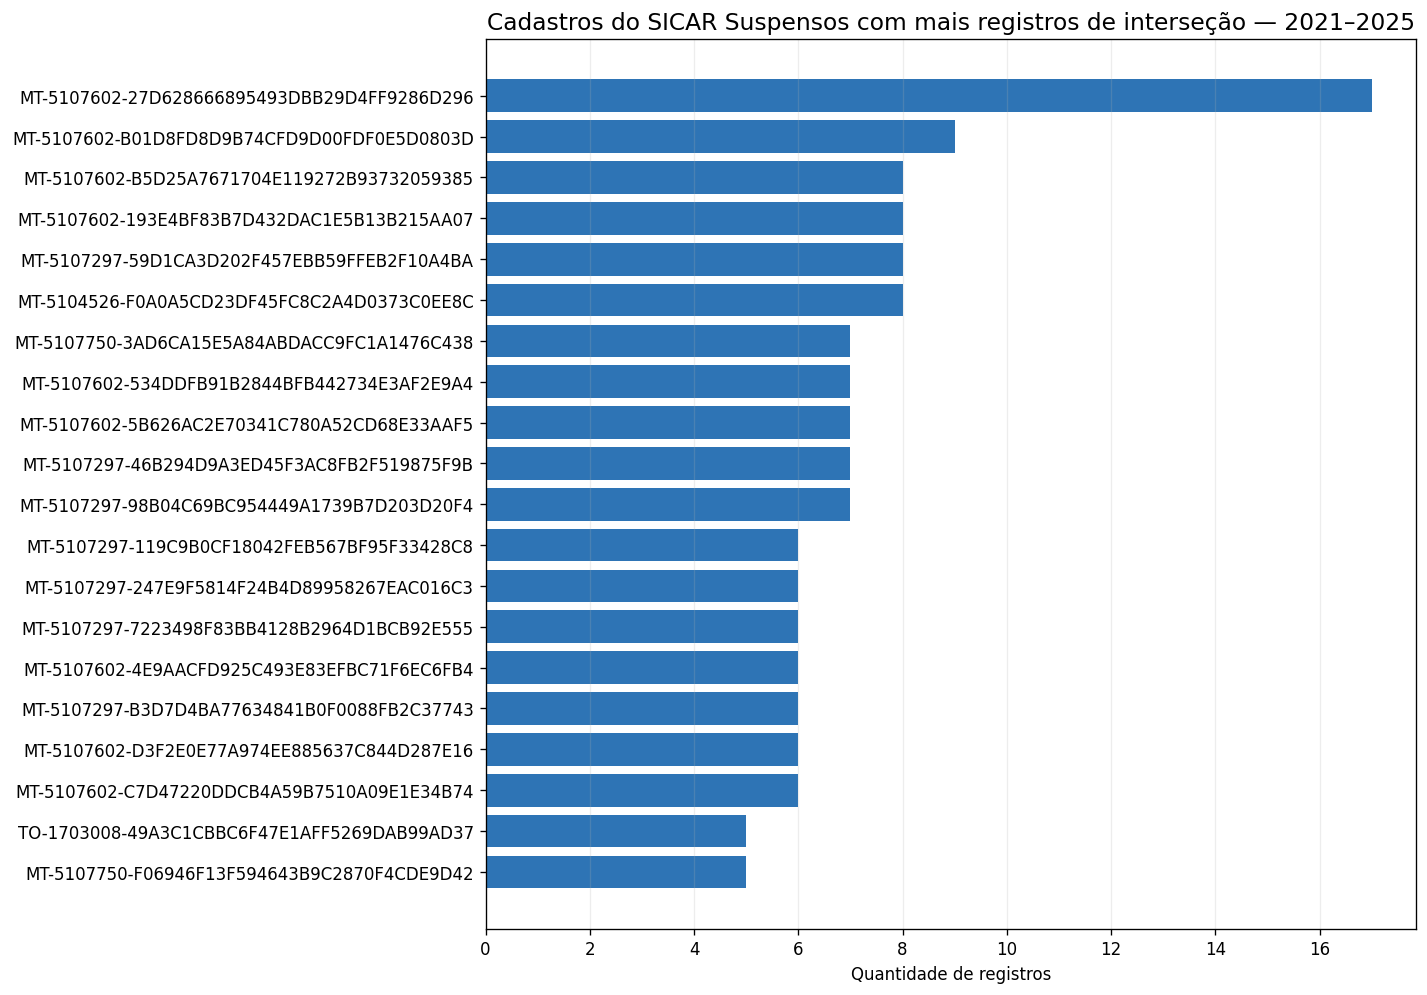

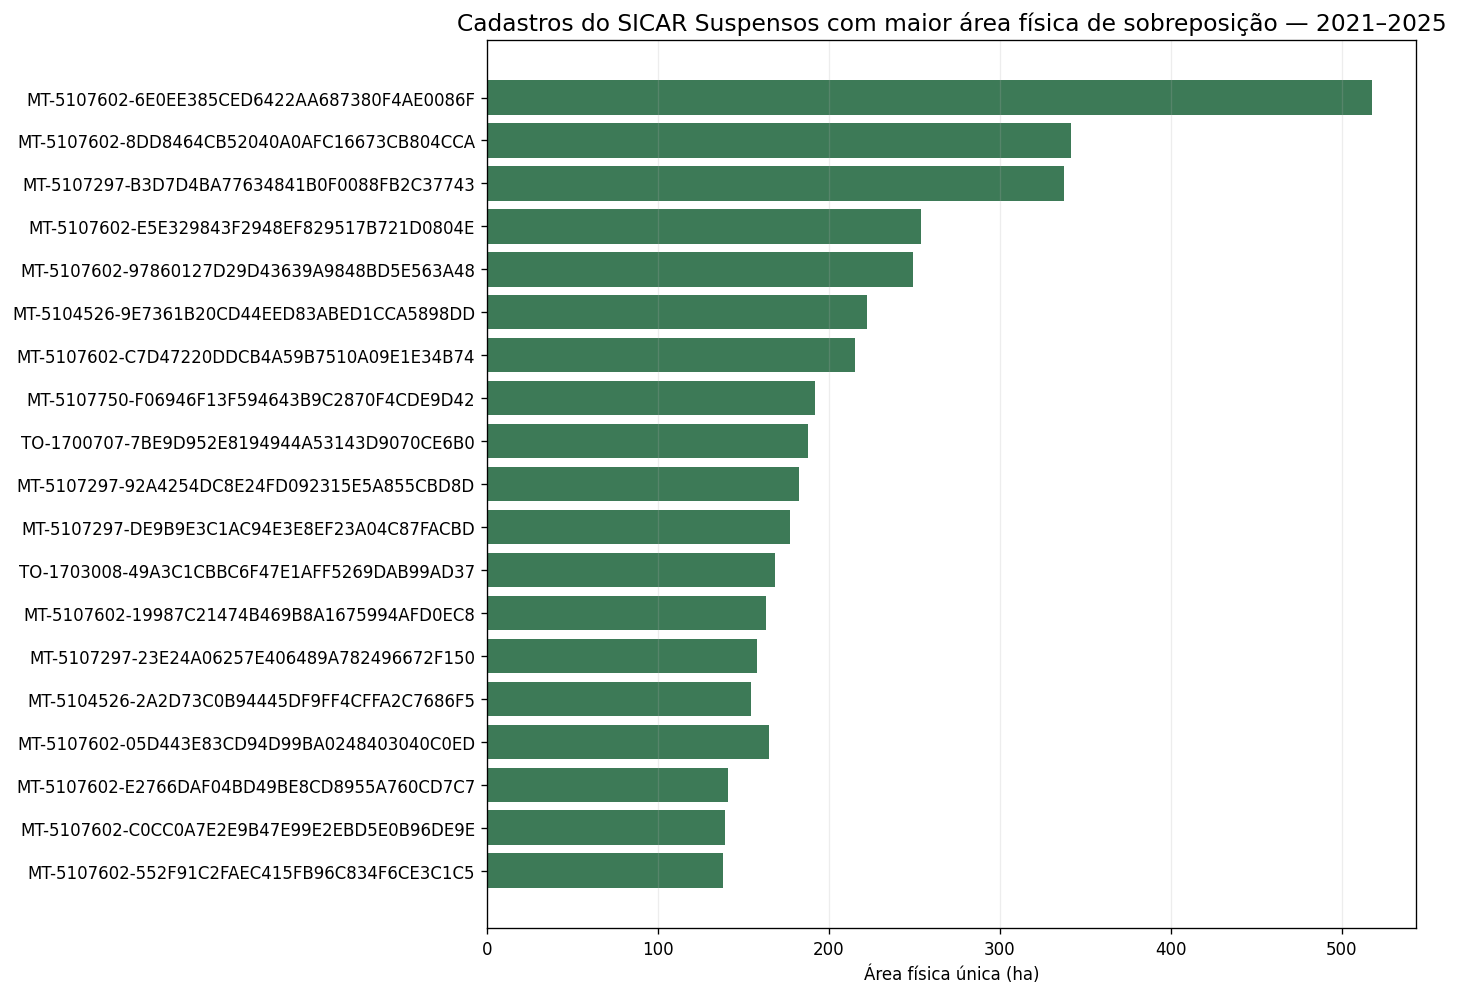

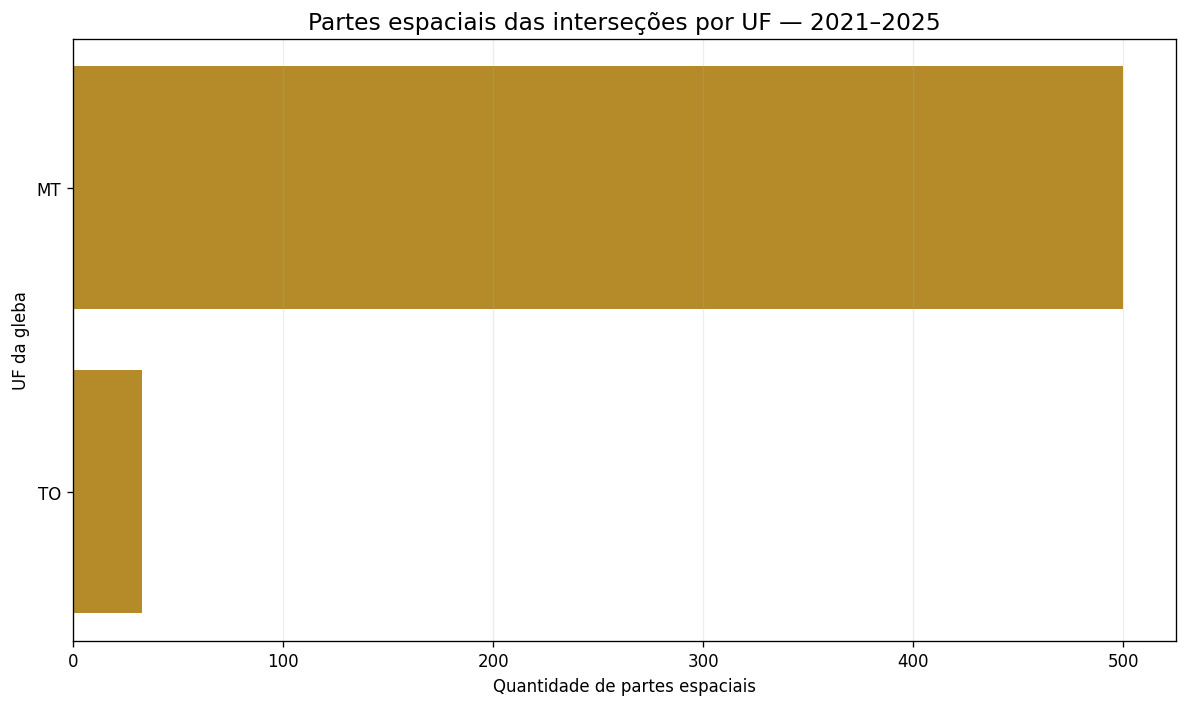

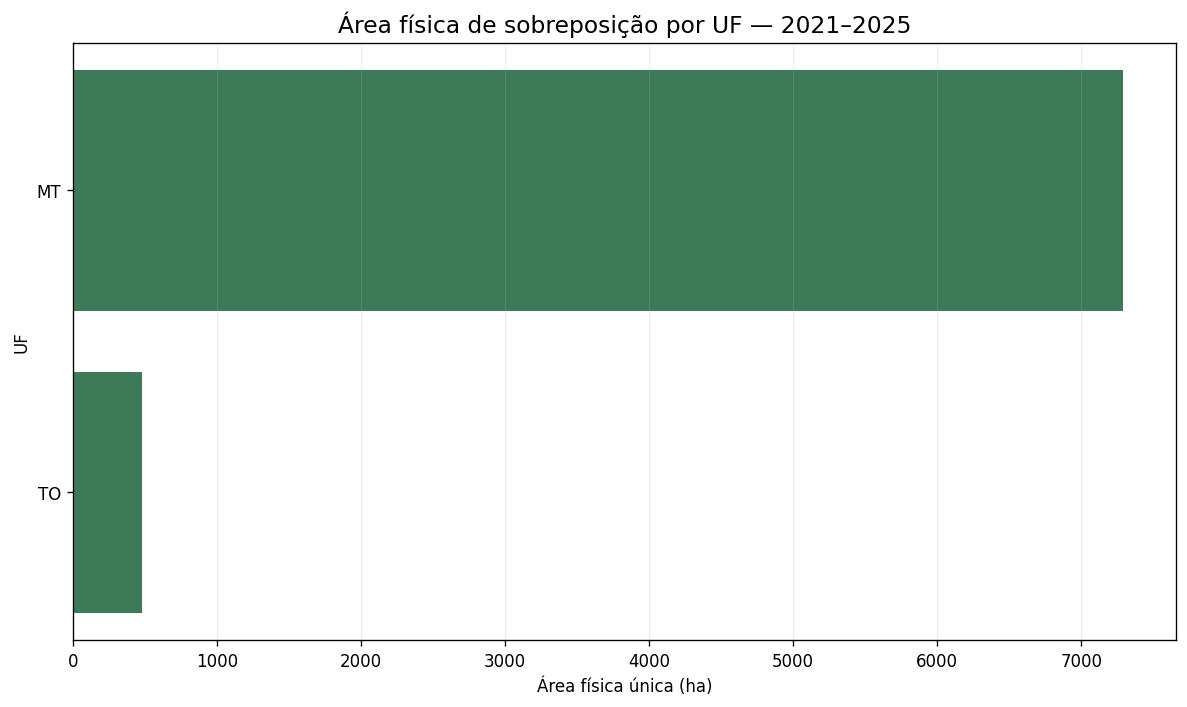

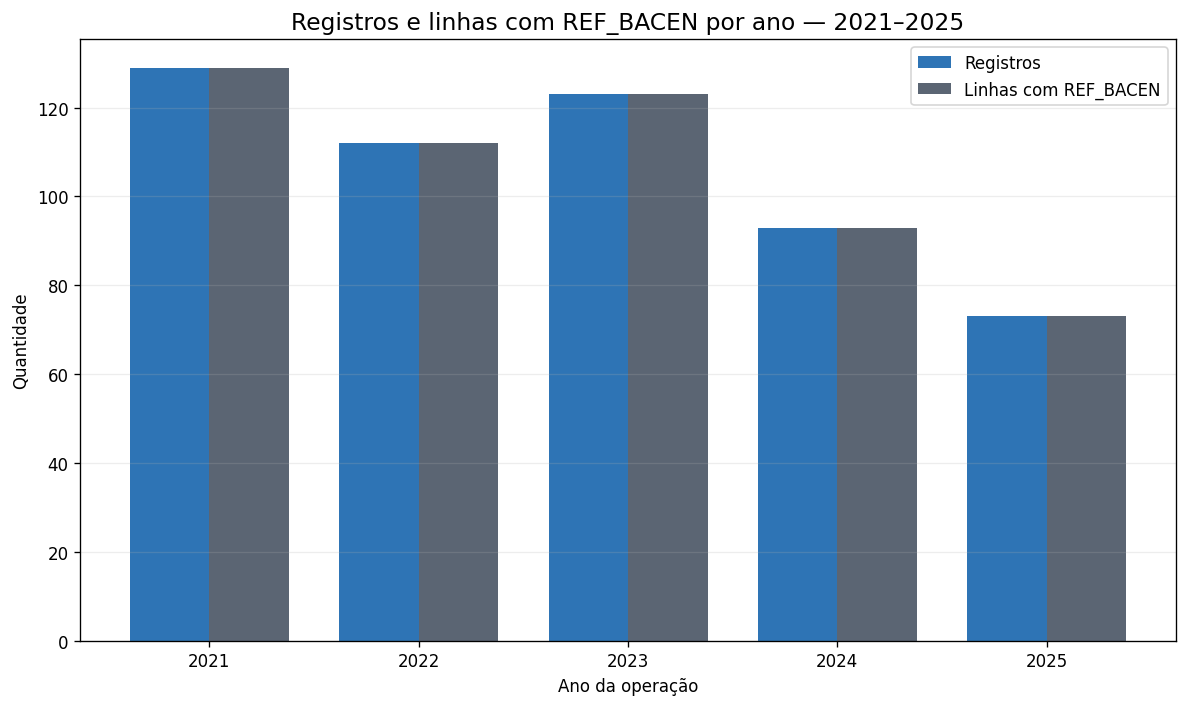

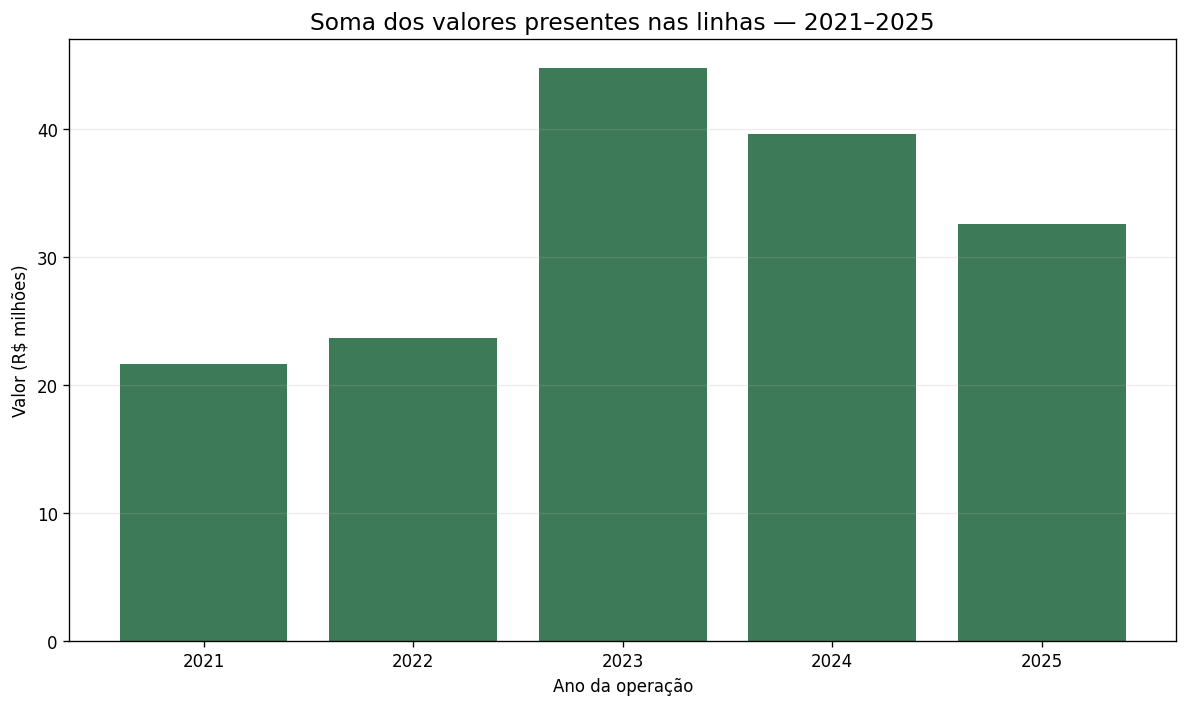

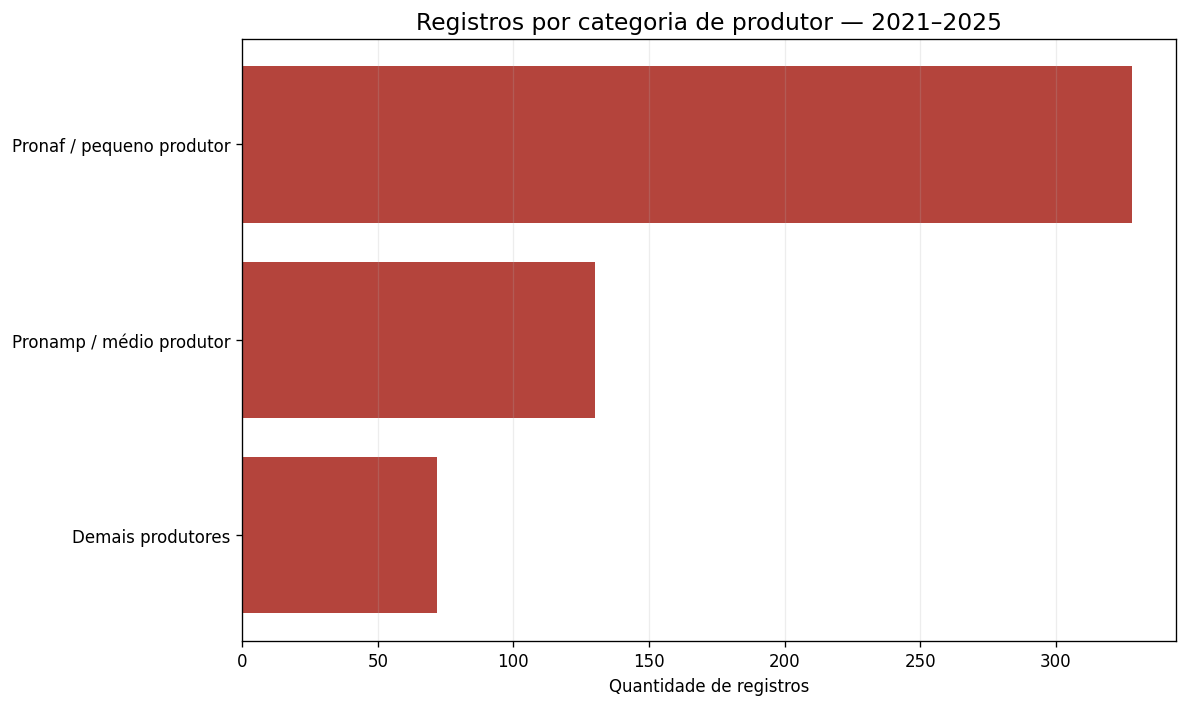

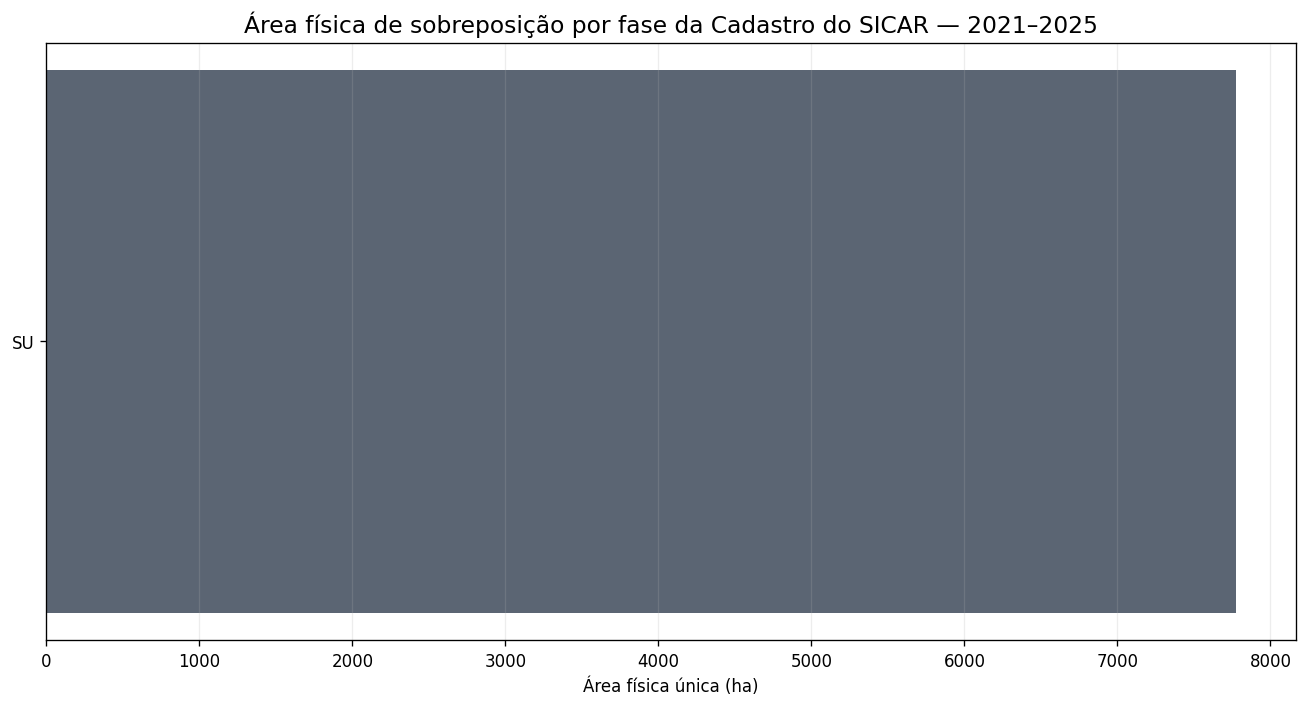

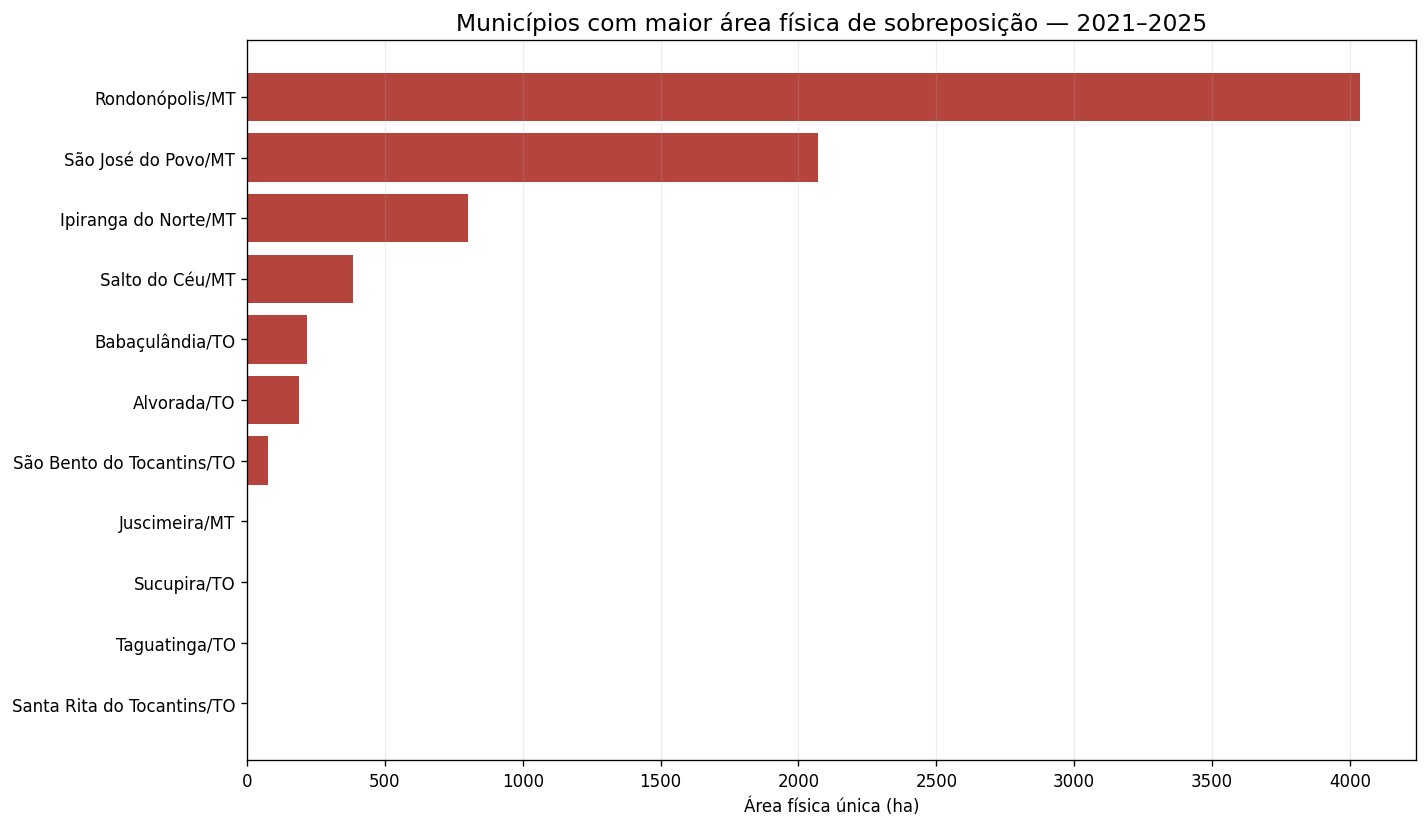

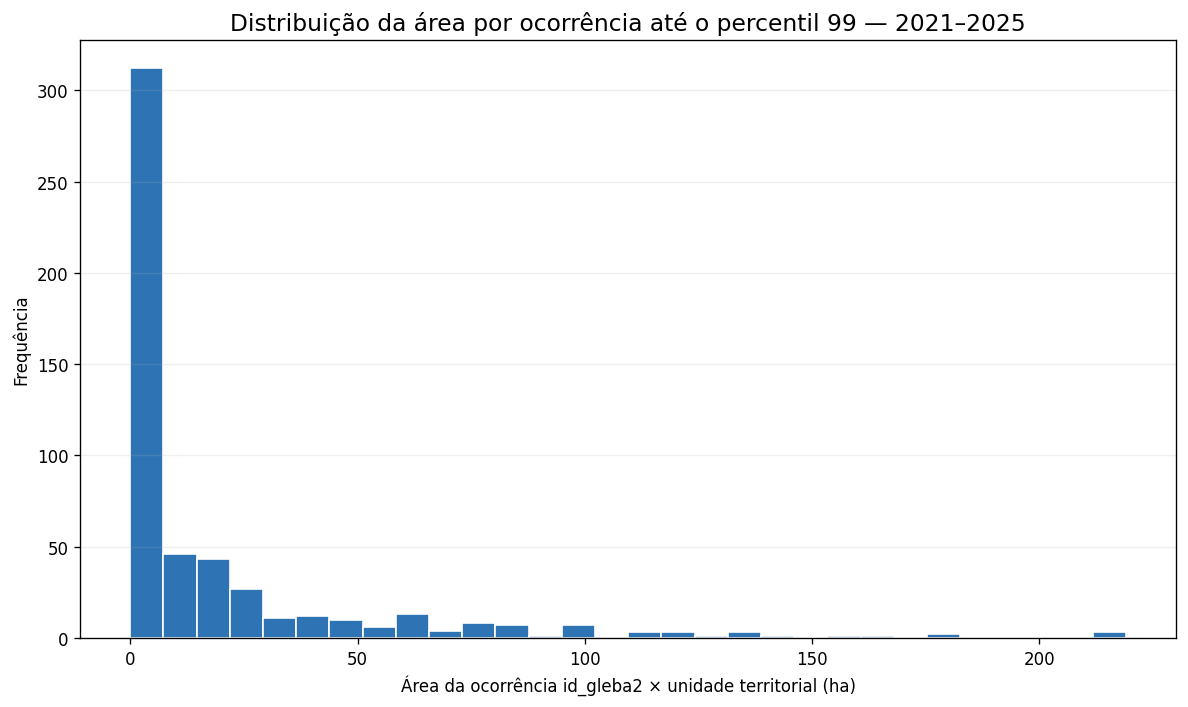

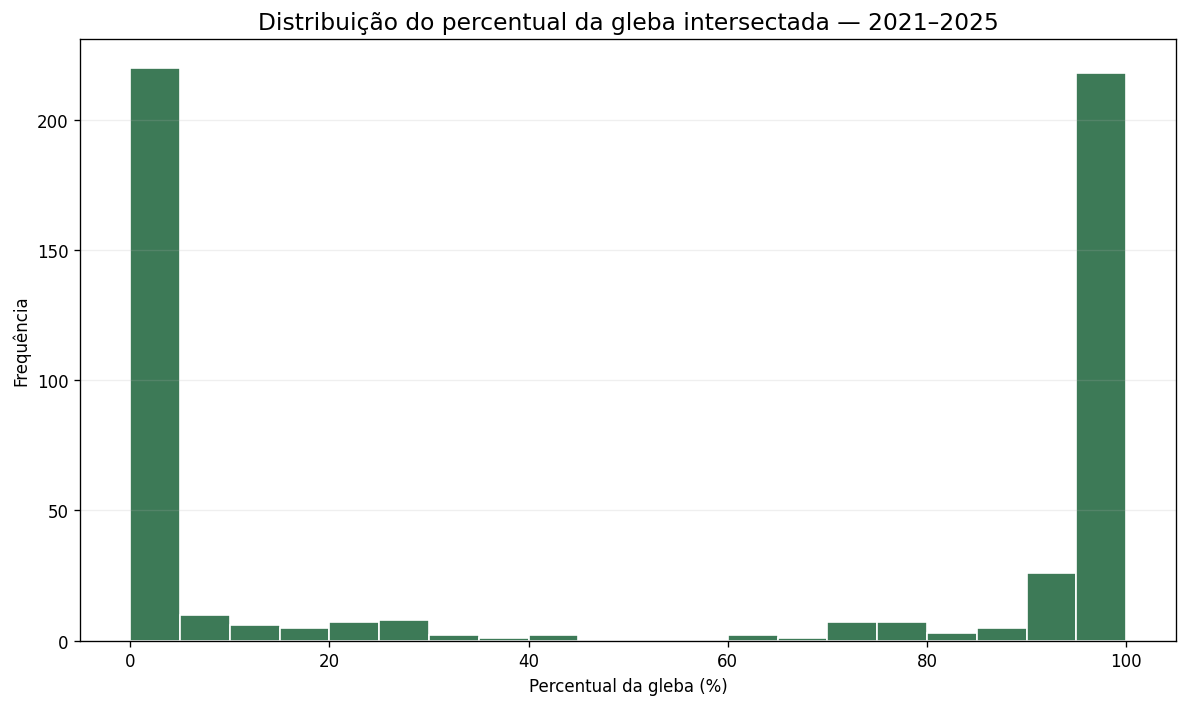

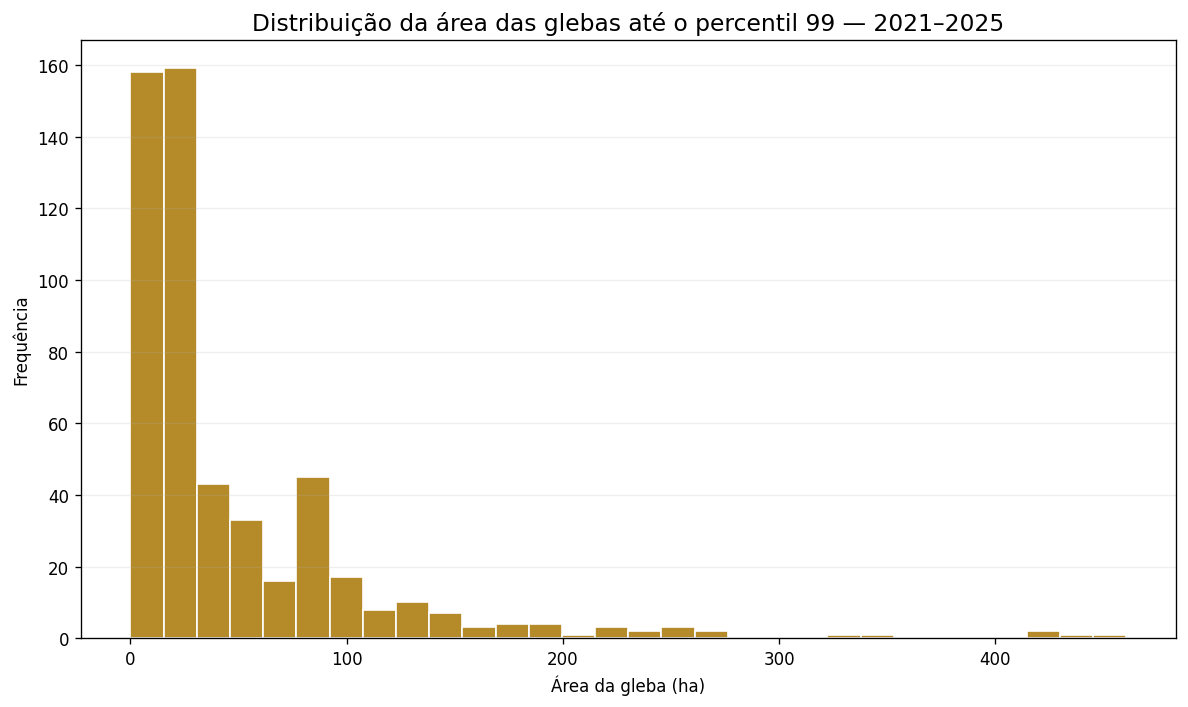

Gráficos e histogramas gerados: 12


In [11]:
# ============================================================
# 11. GERAR GRÁFICOS E HISTOGRAMAS
# ============================================================

COR_AZUL = "#2E74B5"
COR_VERDE = "#3D7A57"
COR_VERMELHO = "#B4443C"
COR_DOURADO = "#B58B2A"
COR_CINZA = "#5B6573"

graficos = OrderedDict()

def salvar_figura(chave, nome):
    caminho = PASTA_GRAFICOS / nome
    plt.tight_layout()
    plt.savefig(caminho, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    graficos[chave] = caminho
    return caminho


top_unidade_glebas = resumo_unidade.nlargest(TOP_N, "QUANTIDADE_REGISTROS").sort_values("QUANTIDADE_REGISTROS")
plt.figure(figsize=(12, max(7, len(top_unidade_glebas) * 0.42)))
plt.barh(top_unidade_glebas["_UNIDADE_NOME"], top_unidade_glebas["QUANTIDADE_REGISTROS"], color=COR_AZUL)
plt.title(f"Cadastros do SICAR Suspensos com mais registros de interseção — {PERIODO_CURTO}")
plt.xlabel("Quantidade de registros")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("unidade_glebas", "01_top_unidades_por_glebas.png")

top_unidade_area = resumo_unidade.nlargest(TOP_N, "AREA_FISICA_UNICA_HA").sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(12, max(7, len(top_unidade_area) * 0.42)))
plt.barh(top_unidade_area["_UNIDADE_NOME"], top_unidade_area["AREA_FISICA_UNICA_HA"], color=COR_VERDE)
plt.title(f"Cadastros do SICAR Suspensos com maior área física de sobreposição — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("unidade_area", "02_top_unidades_por_area_fisica.png")

uf_plot = resumo_uf.sort_values("QUANTIDADE_PARTES_ESPACIAIS")
plt.figure(figsize=(10, max(6, len(uf_plot) * 0.45)))
plt.barh(uf_plot["UF"].astype(str), uf_plot["QUANTIDADE_PARTES_ESPACIAIS"], color=COR_DOURADO)
plt.title(f"Partes espaciais das interseções por UF — {PERIODO_CURTO}")
plt.xlabel("Quantidade de partes espaciais")
plt.ylabel("UF da gleba")
plt.grid(axis="x", alpha=0.22)
salvar_figura("uf_glebas", "03_glebas_por_uf.png")

uf_area_plot = resumo_uf.sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(10, max(6, len(uf_area_plot) * 0.45)))
plt.barh(uf_area_plot["UF"].astype(str), uf_area_plot["AREA_FISICA_UNICA_HA"], color=COR_VERDE)
plt.title(f"Área física de sobreposição por UF — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("UF")
plt.grid(axis="x", alpha=0.22)
salvar_figura("uf_area", "04_area_fisica_por_uf.png")

plt.figure(figsize=(10, 6))
x = np.arange(len(resumo_ano))
largura = 0.38
plt.bar(x - largura/2, resumo_ano["QUANTIDADE_REGISTROS"], width=largura, label="Registros", color=COR_AZUL)
plt.bar(x + largura/2, resumo_ano["QUANTIDADE_REF_BACEN_PREENCHIDOS"], width=largura, label="Linhas com REF_BACEN", color=COR_CINZA)
plt.xticks(x, resumo_ano["_ANO"].astype("Int64").astype(str))
plt.title(f"Registros e linhas com REF_BACEN por ano — {PERIODO_CURTO}")
plt.xlabel("Ano da operação")
plt.ylabel("Quantidade")
plt.legend()
plt.grid(axis="y", alpha=0.22)
salvar_figura("ano_contagens", "05_glebas_e_operacoes_por_ano.png")

if resumo_ano["VALOR_TOTAL_LINHAS_R"].notna().any():
    plt.figure(figsize=(10, 6))
    plt.bar(resumo_ano["_ANO"].astype("Int64").astype(str), resumo_ano["VALOR_TOTAL_LINHAS_R"] / 1_000_000, color=COR_VERDE)
    plt.title(f"Soma dos valores presentes nas linhas — {PERIODO_CURTO}")
    plt.xlabel("Ano da operação")
    plt.ylabel("Valor (R$ milhões)")
    plt.grid(axis="y", alpha=0.22)
    salvar_figura("ano_valor", "06_valor_operacoes_por_ano.png")

if not resumo_produtor.empty:
    produtor_plot = resumo_produtor.sort_values("QUANTIDADE_REGISTROS")
    plt.figure(figsize=(10, 6))
    plt.barh(produtor_plot["_TIPO_PRODUTOR"], produtor_plot["QUANTIDADE_REGISTROS"], color=COR_VERMELHO)
    plt.title(f"Registros por categoria de produtor — {PERIODO_CURTO}")
    plt.xlabel("Quantidade de registros")
    plt.ylabel("")
    plt.grid(axis="x", alpha=0.22)
    salvar_figura("produtor_refs", "07_operacoes_por_tipo_produtor.png")

fase_plot = resumo_tipologia_1[resumo_tipologia_1["_TIPOLOGIA_1"].ne("Não informado")].sort_values("AREA_FISICA_UNICA_HA")
if not fase_plot.empty:
    plt.figure(figsize=(11, max(6, len(fase_plot) * 0.5)))
    plt.barh(fase_plot["_TIPOLOGIA_1"], fase_plot["AREA_FISICA_UNICA_HA"], color=COR_CINZA)
    plt.title(f"Área física de sobreposição por fase da Cadastro do SICAR — {PERIODO_CURTO}")
    plt.xlabel("Área física única (ha)")
    plt.ylabel("")
    plt.grid(axis="x", alpha=0.22)
    salvar_figura("fase_area", "08_area_por_tipologia_1.png")

top_municipios_plot = resumo_municipio.head(TOP_N).copy()
top_municipios_plot["MUNICIPIO_UF"] = top_municipios_plot["MUNICIPIO"] + "/" + top_municipios_plot["UF"]
top_municipios_plot = top_municipios_plot.sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(12, max(7, len(top_municipios_plot) * 0.42)))
plt.barh(top_municipios_plot["MUNICIPIO_UF"], top_municipios_plot["AREA_FISICA_UNICA_HA"], color=COR_VERMELHO)
plt.title(f"Municípios com maior área física de sobreposição — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("municipios_area", "09_top_municipios_por_area_fisica.png")

# Histogramas calculados com todas as linhas; o percentil 99 limita apenas o eixo visual.
areas_intersecao = gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"].dropna()
if not areas_intersecao.empty:
    p99_area = areas_intersecao.quantile(0.99)
    plt.figure(figsize=(10, 6))
    plt.hist(areas_intersecao[areas_intersecao <= p99_area], bins=30, color=COR_AZUL, edgecolor="white")
    plt.title(f"Distribuição da área por ocorrência até o percentil 99 — {PERIODO_CURTO}")
    plt.xlabel("Área da ocorrência id_gleba2 × unidade territorial (ha)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_area_intersecao", "10_histograma_area_intersecao_p99.png")

percentuais = gdf_ocorrencias["_PERCENTUAL_GLEBA"].dropna()
if not percentuais.empty:
    plt.figure(figsize=(10, 6))
    plt.hist(percentuais.clip(0, 100), bins=np.arange(0, 105, 5), color=COR_VERDE, edgecolor="white")
    plt.title(f"Distribuição do percentual da gleba intersectada — {PERIODO_CURTO}")
    plt.xlabel("Percentual da gleba (%)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_percentual", "11_histograma_percentual_gleba.png")

areas_gleba = gdf_glebas["_AREA_GLEBA_GEOM_HA"].dropna()
if not areas_gleba.empty:
    p99_gleba = areas_gleba.quantile(0.99)
    plt.figure(figsize=(10, 6))
    plt.hist(areas_gleba[areas_gleba <= p99_gleba], bins=30, color=COR_DOURADO, edgecolor="white")
    plt.title(f"Distribuição da área das glebas até o percentil 99 — {PERIODO_CURTO}")
    plt.xlabel("Área da gleba (ha)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_area_gleba", "12_histograma_area_gleba_p99.png")

print("Gráficos e histogramas gerados:", len(graficos))


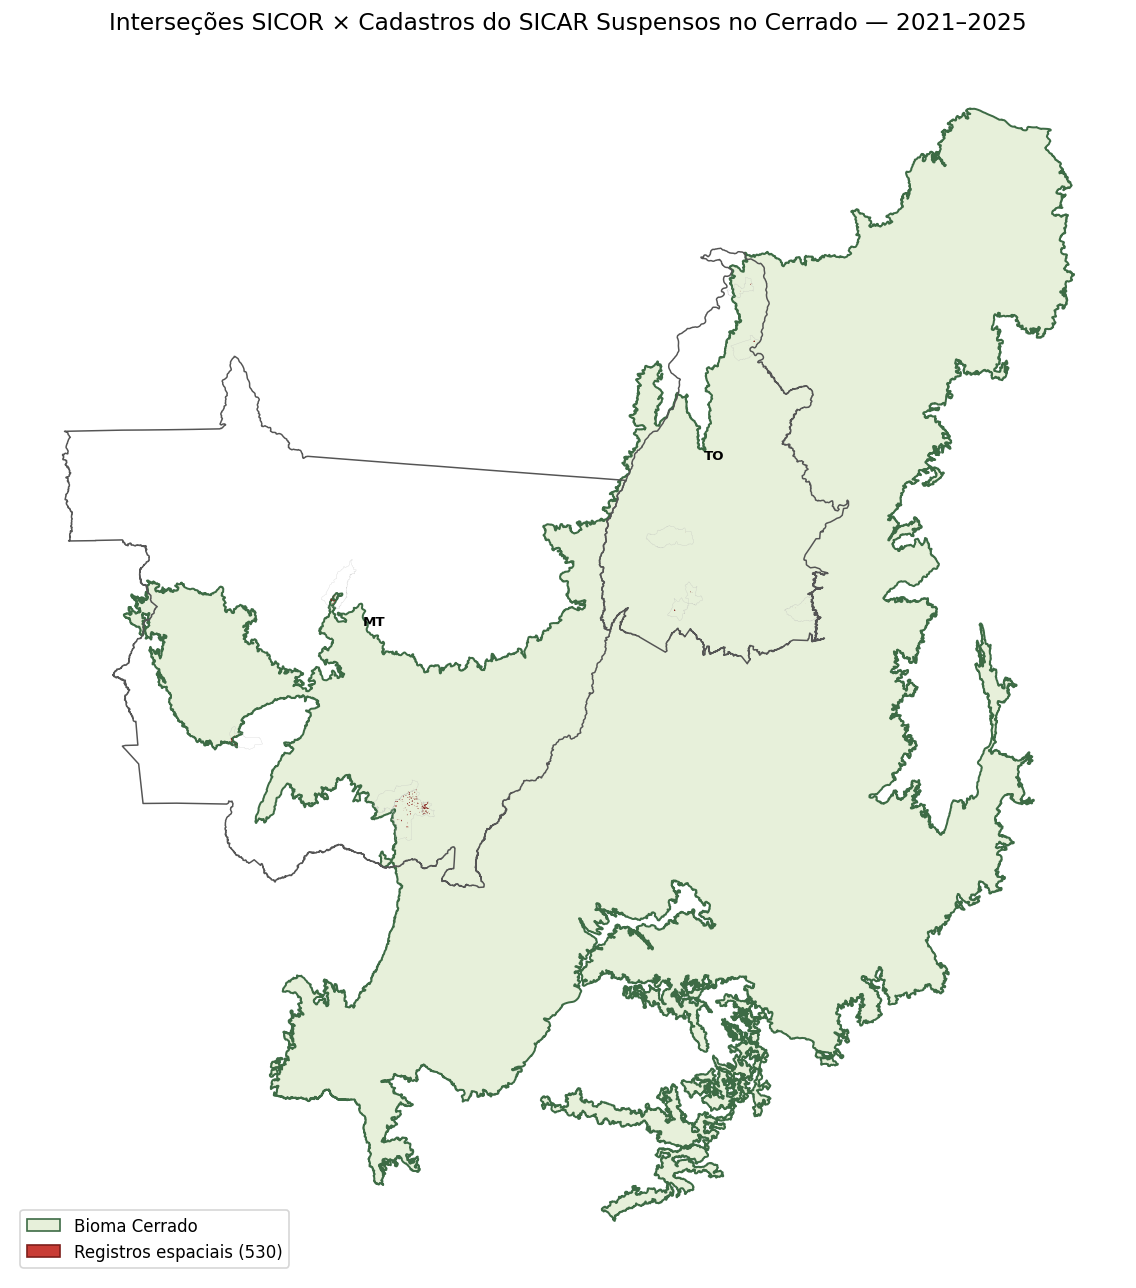

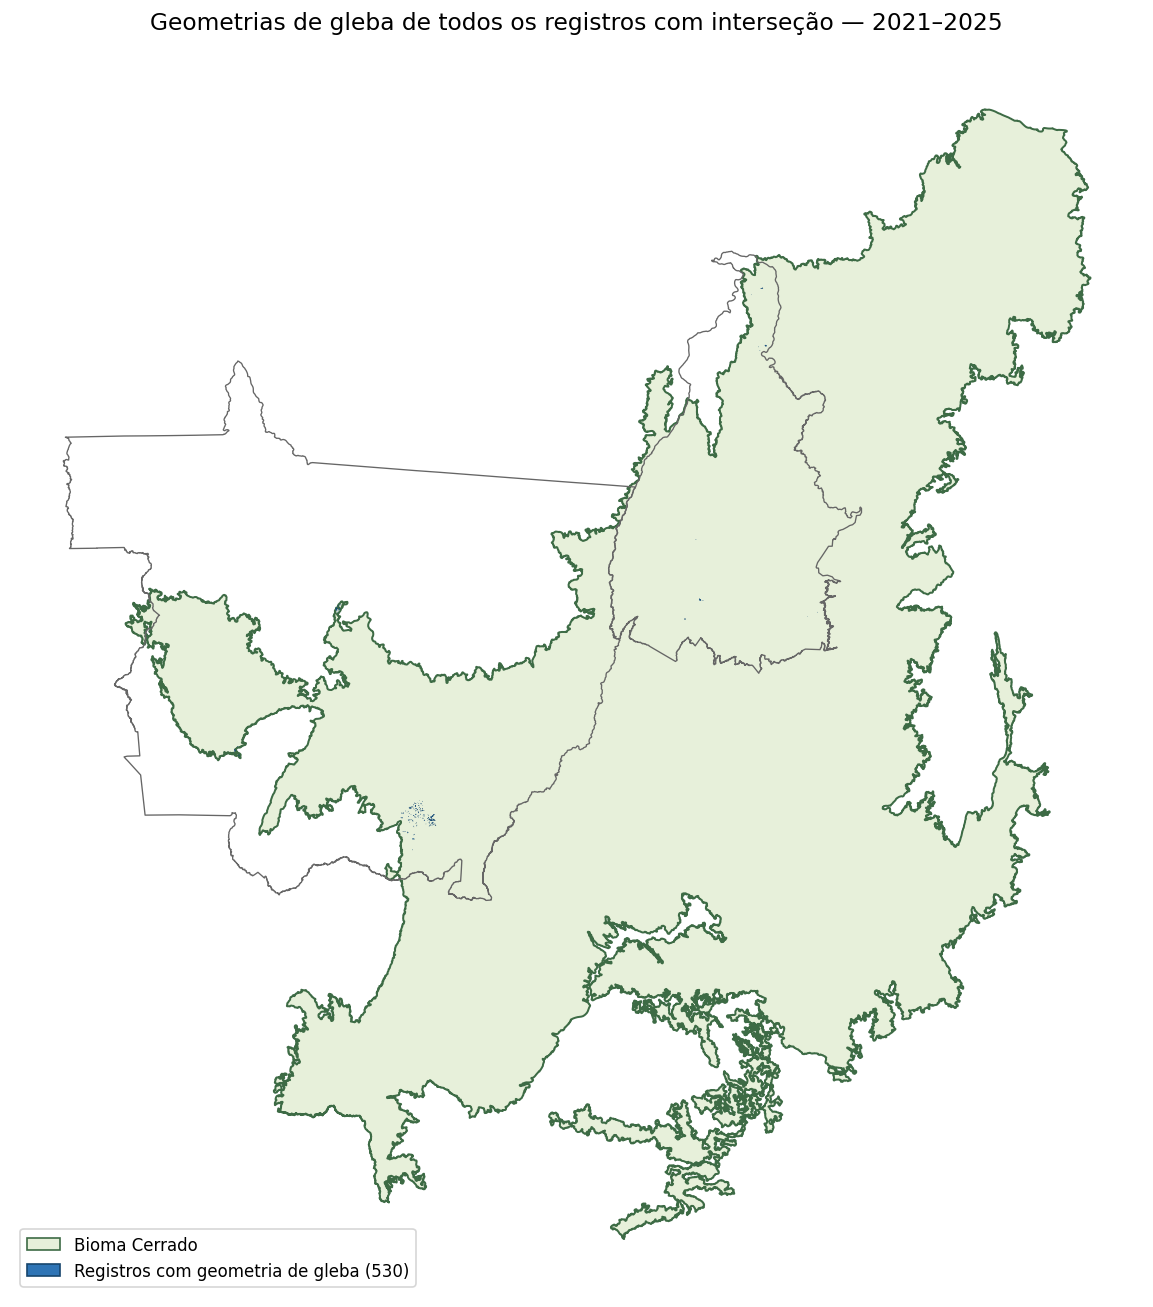

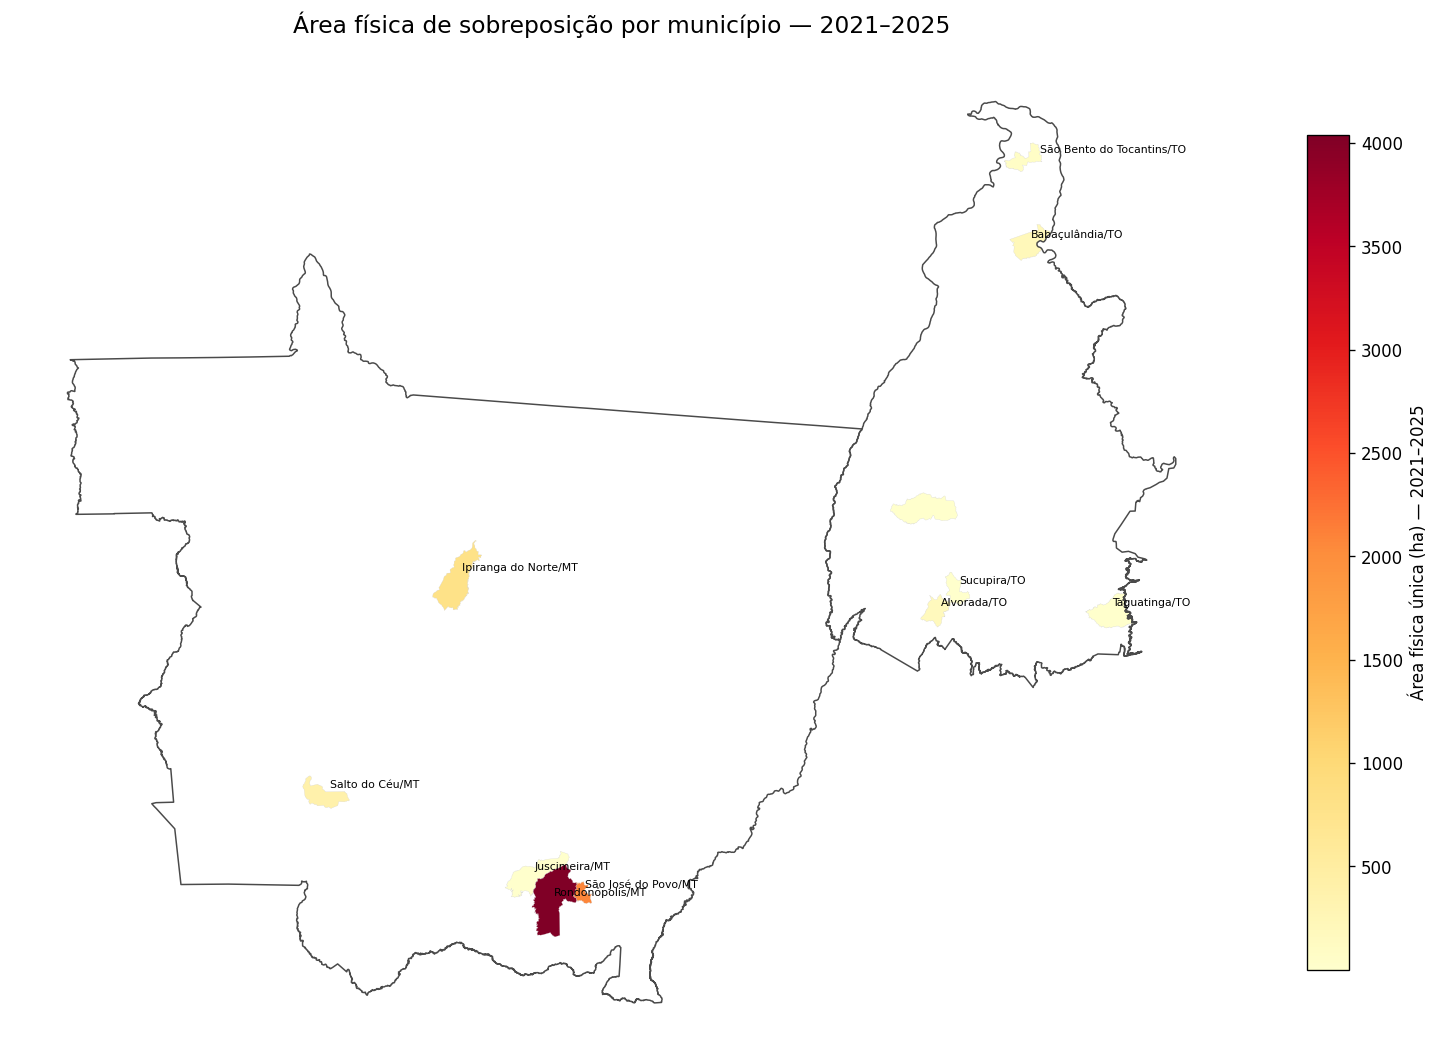

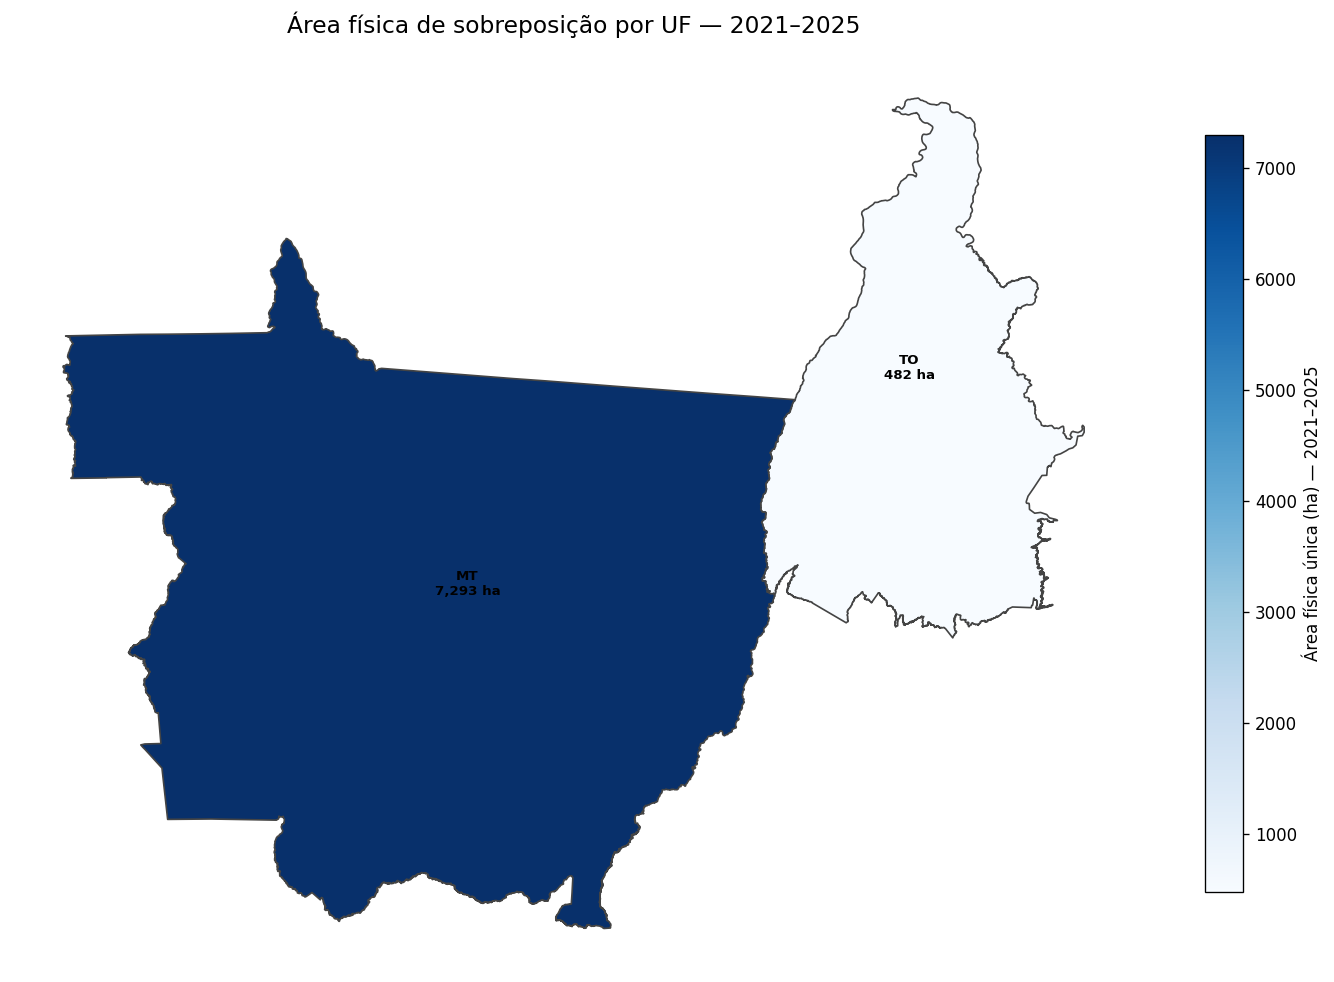

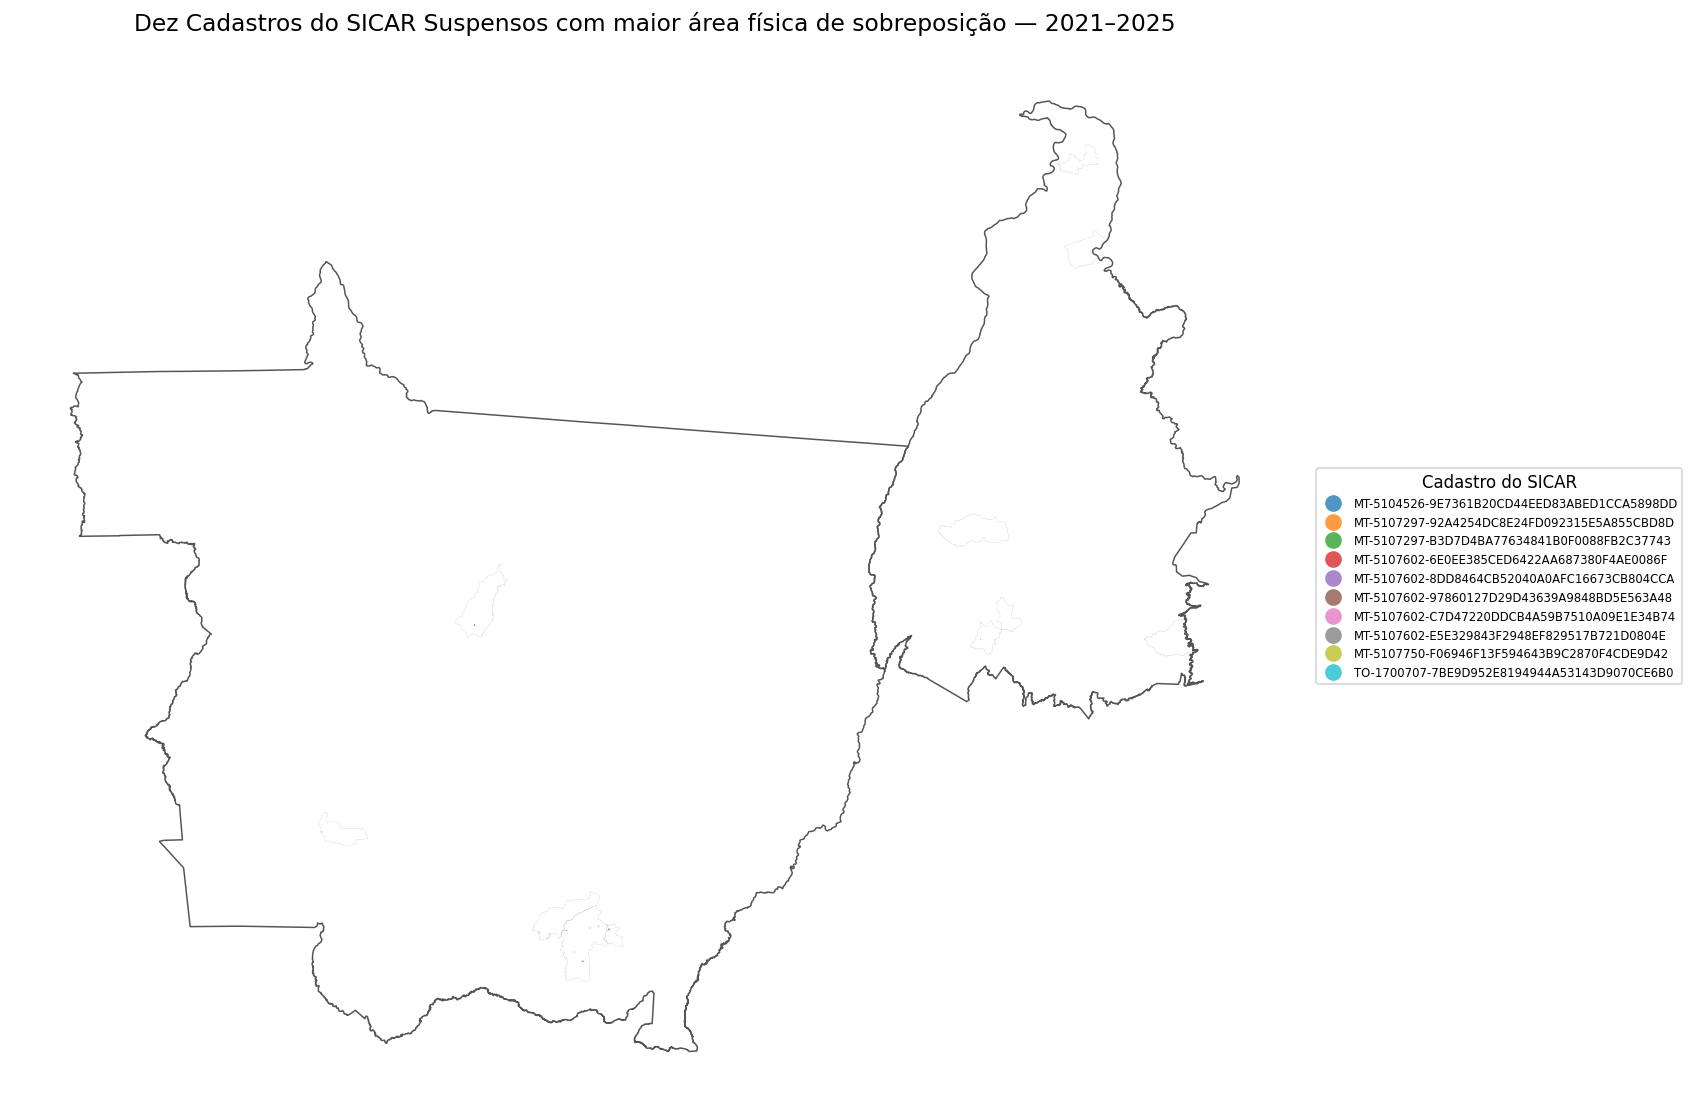

Mapas gerados: 5


In [12]:
# ============================================================
# 12. PREPARAR CAMADAS TEMÁTICAS E GERAR MAPAS
# ============================================================

mapas = OrderedDict()

def salvar_mapa(chave, nome):
    caminho = PASTA_MAPAS / nome
    plt.tight_layout()
    plt.savefig(caminho, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    mapas[chave] = caminho
    return caminho


cerrado_mapa = cerrado.to_crs(CRS_AREA)
estados_mapa = estados_relevantes.to_crs(CRS_AREA)
municipios_mapa = municipios_relevantes.to_crs(CRS_AREA)
ocorrencias_mapa = gdf_ocorrencias.to_crs(CRS_AREA)
glebas_mapa = gdf_glebas.to_crs(CRS_AREA)

# 1. Mapa geral das ocorrências.
fig, ax = plt.subplots(figsize=(13, 11))
cerrado_mapa.plot(ax=ax, facecolor="#E7F0DA", edgecolor="#3D6B45", linewidth=1.2, zorder=1)
municipios_mapa.boundary.plot(ax=ax, color="#B9B9B9", linewidth=0.18, alpha=0.7, zorder=2)
estados_mapa.boundary.plot(ax=ax, color="#555555", linewidth=0.9, zorder=3)
ocorrencias_mapa.plot(ax=ax, facecolor="#C83C35", edgecolor="#7E1F1B", linewidth=0.15, alpha=0.72, rasterized=True, zorder=4)
for _, linha in estados_mapa.iterrows():
    ponto = linha.geometry.representative_point()
    ax.text(ponto.x, ponto.y, linha["UF"], fontsize=8, fontweight="bold", ha="center", va="center", zorder=5)
ax.set_title(f"Interseções SICOR × Cadastros do SICAR Suspensos no Cerrado — {PERIODO_CURTO}", pad=14)
ax.legend(handles=[
    Patch(facecolor="#E7F0DA", edgecolor="#3D6B45", label="Bioma Cerrado"),
    Patch(facecolor="#C83C35", edgecolor="#7E1F1B", label=f"Registros espaciais ({len(gdf_ocorrencias):,})"),
], loc="lower left")
ax.set_axis_off()
salvar_mapa("geral", "01_mapa_geral_intersecoes.png")

# 2. Mapa das geometrias de gleba presentes em todos os registros.
fig, ax = plt.subplots(figsize=(13, 11))
cerrado_mapa.plot(ax=ax, facecolor="#E7F0DA", edgecolor="#3D6B45", linewidth=1.2, zorder=1)
estados_mapa.boundary.plot(ax=ax, color="#666666", linewidth=0.8, zorder=2)
glebas_mapa.plot(ax=ax, facecolor="#2E74B5", edgecolor="#17466D", linewidth=0.15, alpha=0.62, rasterized=True, zorder=3)
ax.set_title(f"Geometrias de gleba de todos os registros com interseção — {PERIODO_CURTO}", pad=14)
ax.legend(handles=[
    Patch(facecolor="#E7F0DA", edgecolor="#3D6B45", label="Bioma Cerrado"),
    Patch(facecolor="#2E74B5", edgecolor="#17466D", label=f"Registros com geometria de gleba ({len(gdf_glebas):,})"),
], loc="lower left")
ax.set_axis_off()
salvar_mapa("glebas", "02_mapa_geometrias_glebas_todos_registros.png")

# Camadas municipais e estaduais com área física única.
municipios_tema = municipios_relevantes.merge(
    resumo_municipio[["COD_MUNICIPIO", "AREA_FISICA_UNICA_HA"]],
    on="COD_MUNICIPIO", how="left", validate="one_to_one",
)
municipios_tema["AREA_FISICA_UNICA_HA"] = municipios_tema["AREA_FISICA_UNICA_HA"].fillna(0)

estados_tema = estados_relevantes.merge(
    resumo_uf[["UF", "AREA_FISICA_UNICA_HA"]],
    on="UF", how="left", validate="one_to_one",
)
estados_tema["AREA_FISICA_UNICA_HA"] = estados_tema["AREA_FISICA_UNICA_HA"].fillna(0)

fig, ax = plt.subplots(figsize=(13, 11))
municipios_tema.to_crs(CRS_AREA).plot(
    ax=ax, column="AREA_FISICA_UNICA_HA", cmap="YlOrRd", legend=True,
    linewidth=0.15, edgecolor="#D0D0D0",
    legend_kwds={"label": f"Área física única (ha) — {PERIODO_CURTO}", "shrink": 0.65},
)
estados_mapa.boundary.plot(ax=ax, color="#4A4A4A", linewidth=0.9, zorder=3)
for _, linha in resumo_municipio.head(10).iterrows():
    feicao = municipios_tema[municipios_tema["COD_MUNICIPIO"].eq(linha["COD_MUNICIPIO"])].to_crs(CRS_AREA)
    if not feicao.empty:
        ponto = feicao.geometry.iloc[0].representative_point()
        ax.annotate(f"{linha['MUNICIPIO']}/{linha['UF']}", (ponto.x, ponto.y), xytext=(3, 3), textcoords="offset points", fontsize=6.5)
ax.set_title(f"Área física de sobreposição por município — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("municipios", "03_mapa_area_por_municipio.png")

fig, ax = plt.subplots(figsize=(12, 10))
estados_tema.to_crs(CRS_AREA).plot(
    ax=ax, column="AREA_FISICA_UNICA_HA", cmap="Blues", legend=True,
    linewidth=1.0, edgecolor="#444444",
    legend_kwds={"label": f"Área física única (ha) — {PERIODO_CURTO}", "shrink": 0.65},
)
for _, linha in estados_tema.to_crs(CRS_AREA).iterrows():
    ponto = linha.geometry.representative_point()
    ax.text(ponto.x, ponto.y, f"{linha['UF']}\n{linha['AREA_FISICA_UNICA_HA']:,.0f} ha", ha="center", va="center", fontsize=8, fontweight="bold")
ax.set_title(f"Área física de sobreposição por UF — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("ufs", "04_mapa_area_por_uf.png")

# 5. Localização das dez unidades territoriais com maior área física de sobreposição.
top_ids = resumo_unidade.head(TOP_MAPA)["_UNIDADE_ID"].tolist()
top_mapa = gdf_ocorrencias[gdf_ocorrencias["_UNIDADE_ID"].isin(top_ids)].to_crs(CRS_AREA)
fig, ax = plt.subplots(figsize=(14, 11))
municipios_mapa.boundary.plot(ax=ax, color="#C5C5C5", linewidth=0.16, zorder=1)
estados_mapa.boundary.plot(ax=ax, color="#555555", linewidth=0.9, zorder=2)
top_mapa.plot(
    ax=ax, column="_UNIDADE_NOME", categorical=True, legend=True,
    alpha=0.78, linewidth=0.15, zorder=3,
    legend_kwds={"title": "Cadastro do SICAR", "loc": "center left", "bbox_to_anchor": (1.01, 0.5), "fontsize": 7},
)
ax.set_title(f"Dez Cadastros do SICAR Suspensos com maior área física de sobreposição — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("top_unidades", "05_mapa_top_unidades_territoriais.png")

print("Mapas gerados:", len(mapas))


In [13]:
# ============================================================
# 13. FUNÇÕES DE FORMATAÇÃO DO WORD
# ============================================================

AZUL = "2E74B5"
AZUL_ESCURO = "1F4D78"
CINZA_CLARO = "F2F4F7"
CINZA_TEXTO = "59636E"

def br_inteiro(valor):
    if pd.isna(valor): return "-"
    return f"{int(round(float(valor))):,}".replace(",", ".")

def br_decimal(valor, casas=2):
    if pd.isna(valor): return "-"
    texto = f"{float(valor):,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

def br_moeda(valor):
    return "-" if pd.isna(valor) else f"R$ {br_decimal(valor, 2)}"

def br_percentual(valor):
    return "-" if pd.isna(valor) else f"{br_decimal(valor, 2)}%"

def br_generico(valor):
    if pd.isna(valor): return "-"
    if isinstance(valor, (int, np.integer)): return br_inteiro(valor)
    if isinstance(valor, (float, np.floating)): return br_decimal(valor, 2)
    return str(valor)

def definir_fonte_run(run, nome="Calibri", tamanho=11, cor=None, negrito=None, italico=None):
    run.font.name = nome
    run._element.get_or_add_rPr().rFonts.set(qn("w:ascii"), nome)
    run._element.get_or_add_rPr().rFonts.set(qn("w:hAnsi"), nome)
    run.font.size = Pt(tamanho)
    if cor: run.font.color.rgb = RGBColor.from_string(cor)
    if negrito is not None: run.bold = negrito
    if italico is not None: run.italic = italico

def sombrear_celula(celula, preenchimento):
    tc_pr = celula._tc.get_or_add_tcPr()
    shd = tc_pr.find(qn("w:shd"))
    if shd is None:
        shd = OxmlElement("w:shd")
        tc_pr.append(shd)
    shd.set(qn("w:fill"), preenchimento)

def margens_celula(celula, top=80, start=120, bottom=80, end=120):
    tc_pr = celula._tc.get_or_add_tcPr()
    tc_mar = tc_pr.first_child_found_in("w:tcMar")
    if tc_mar is None:
        tc_mar = OxmlElement("w:tcMar")
        tc_pr.append(tc_mar)
    for lado, valor in [("top", top), ("start", start), ("bottom", bottom), ("end", end)]:
        elemento = tc_mar.find(qn(f"w:{lado}"))
        if elemento is None:
            elemento = OxmlElement(f"w:{lado}")
            tc_mar.append(elemento)
        elemento.set(qn("w:w"), str(valor))
        elemento.set(qn("w:type"), "dxa")

def repetir_cabecalho(linha):
    tr_pr = linha._tr.get_or_add_trPr()
    elemento = OxmlElement("w:tblHeader")
    elemento.set(qn("w:val"), "true")
    tr_pr.append(elemento)

def definir_larguras_tabela(tabela, larguras_dxa):
    total = sum(larguras_dxa)
    tabela.autofit = False
    tbl_pr = tabela._tbl.tblPr
    tbl_w = tbl_pr.find(qn("w:tblW"))
    if tbl_w is None:
        tbl_w = OxmlElement("w:tblW")
        tbl_pr.append(tbl_w)
    tbl_w.set(qn("w:w"), str(total))
    tbl_w.set(qn("w:type"), "dxa")
    tbl_ind = tbl_pr.find(qn("w:tblInd"))
    if tbl_ind is None:
        tbl_ind = OxmlElement("w:tblInd")
        tbl_pr.append(tbl_ind)
    tbl_ind.set(qn("w:w"), "120")
    tbl_ind.set(qn("w:type"), "dxa")
    grid = tabela._tbl.tblGrid
    for filho in list(grid):
        grid.remove(filho)
    for largura in larguras_dxa:
        col = OxmlElement("w:gridCol")
        col.set(qn("w:w"), str(largura))
        grid.append(col)
    for linha in tabela.rows:
        for celula, largura in zip(linha.cells, larguras_dxa):
            tc_w = celula._tc.get_or_add_tcPr().find(qn("w:tcW"))
            if tc_w is None:
                tc_w = OxmlElement("w:tcW")
                celula._tc.get_or_add_tcPr().append(tc_w)
            tc_w.set(qn("w:w"), str(largura))
            tc_w.set(qn("w:type"), "dxa")
            margens_celula(celula)

def adicionar_legenda_tabela(doc, numero, titulo):
    p = doc.add_paragraph()
    p.paragraph_format.space_before = Pt(8)
    p.paragraph_format.space_after = Pt(4)
    p.paragraph_format.keep_with_next = True
    r = p.add_run(f"Tabela {numero} - {titulo} ({PERIODO_CURTO})")
    definir_fonte_run(r, tamanho=9, negrito=True)

def adicionar_fonte(doc, texto):
    p = doc.add_paragraph()
    p.paragraph_format.space_before = Pt(4)
    p.paragraph_format.space_after = Pt(6)
    r = p.add_run(f"Fonte: {texto}")
    definir_fonte_run(r, tamanho=8, cor=CINZA_TEXTO)

def adicionar_tabela(doc, df, colunas, titulos, larguras, formatadores=None, max_linhas=None):
    formatadores = formatadores or {}
    tabela_df = df.head(max_linhas) if max_linhas else df
    tabela = doc.add_table(rows=1, cols=len(colunas))
    tabela.style = "Table Grid"
    tabela.alignment = WD_TABLE_ALIGNMENT.CENTER
    repetir_cabecalho(tabela.rows[0])
    for i, titulo in enumerate(titulos):
        celula = tabela.rows[0].cells[i]
        celula.text = titulo
        celula.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
        sombrear_celula(celula, CINZA_CLARO)
        for p in celula.paragraphs:
            p.alignment = WD_ALIGN_PARAGRAPH.CENTER
            p.paragraph_format.space_after = Pt(0)
            for r in p.runs:
                definir_fonte_run(r, tamanho=8, negrito=True)
    for _, linha in tabela_df.iterrows():
        celulas = tabela.add_row().cells
        for i, coluna in enumerate(colunas):
            valor = linha.get(coluna, pd.NA)
            celulas[i].text = formatadores.get(coluna, br_generico)(valor)
            celulas[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
            for p in celulas[i].paragraphs:
                p.alignment = WD_ALIGN_PARAGRAPH.RIGHT if isinstance(valor, (int, float, np.integer, np.floating)) else WD_ALIGN_PARAGRAPH.LEFT
                p.paragraph_format.space_after = Pt(0)
                p.paragraph_format.line_spacing = 1.0
                for r in p.runs:
                    definir_fonte_run(r, tamanho=7.5)
    definir_larguras_tabela(tabela, larguras)
    return tabela

def adicionar_figura(doc, caminho, numero, titulo, nota=None, largura=6.35):
    caminho = Path(caminho)
    if not caminho.exists(): return
    p_img = doc.add_paragraph()
    p_img.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p_img.paragraph_format.keep_with_next = True
    p_img.add_run().add_picture(str(caminho), width=Inches(largura))
    p = doc.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p.paragraph_format.space_before = Pt(2)
    p.paragraph_format.space_after = Pt(2)
    r = p.add_run(f"Figura {numero} - {titulo} ({PERIODO_CURTO})")
    definir_fonte_run(r, tamanho=9, italico=True)
    if nota:
        n = doc.add_paragraph()
        n.alignment = WD_ALIGN_PARAGRAPH.CENTER
        n.paragraph_format.space_after = Pt(2)
        rn = n.add_run(f"Nota: {nota}")
        definir_fonte_run(rn, tamanho=8, cor=CINZA_TEXTO)
    adicionar_fonte(doc, "elaboração própria a partir da base de interseção SICOR × Cadastros do SICAR Suspensos.")

def adicionar_paragrafo(doc, texto):
    p = doc.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
    p.paragraph_format.space_after = Pt(6)
    p.paragraph_format.line_spacing = 1.10
    r = p.add_run(texto)
    definir_fonte_run(r, tamanho=11)
    return p

def adicionar_numero_pagina(paragrafo):
    paragrafo.alignment = WD_ALIGN_PARAGRAPH.RIGHT
    run = paragrafo.add_run("Página ")
    definir_fonte_run(run, tamanho=8, cor=CINZA_TEXTO)
    fld = OxmlElement("w:fldSimple")
    fld.set(qn("w:instr"), "PAGE")
    paragrafo._p.append(fld)


In [14]:
# ============================================================
# 14. GERAR O RELATÓRIO WORD UNIFICADO
# ============================================================

doc = Document()
secao = doc.sections[0]
secao.page_width = Inches(8.5)
secao.page_height = Inches(11)
secao.top_margin = Inches(1)
secao.bottom_margin = Inches(1)
secao.left_margin = Inches(1)
secao.right_margin = Inches(1)
secao.header_distance = Inches(0.492)
secao.footer_distance = Inches(0.492)

# Preset visual: standard_business_brief.
normal = doc.styles["Normal"]
normal.font.name = "Calibri"
normal._element.rPr.rFonts.set(qn("w:ascii"), "Calibri")
normal._element.rPr.rFonts.set(qn("w:hAnsi"), "Calibri")
normal.font.size = Pt(11)
normal.paragraph_format.space_after = Pt(6)
normal.paragraph_format.line_spacing = 1.10

for nome, tamanho, cor, antes, depois in [
    ("Heading 1", 16, AZUL, 16, 8),
    ("Heading 2", 13, AZUL, 12, 6),
    ("Heading 3", 12, AZUL_ESCURO, 8, 4),
]:
    estilo = doc.styles[nome]
    estilo.font.name = "Calibri"
    estilo._element.rPr.rFonts.set(qn("w:ascii"), "Calibri")
    estilo._element.rPr.rFonts.set(qn("w:hAnsi"), "Calibri")
    estilo.font.size = Pt(tamanho)
    estilo.font.color.rgb = RGBColor.from_string(cor)
    estilo.font.bold = True
    estilo.paragraph_format.space_before = Pt(antes)
    estilo.paragraph_format.space_after = Pt(depois)
    estilo.paragraph_format.keep_with_next = True

# Cabeçalho e rodapé.
cabecalho = secao.header.paragraphs[0]
cabecalho.alignment = WD_ALIGN_PARAGRAPH.LEFT
r = cabecalho.add_run(f"SICOR Cerrado × Cadastros do SICAR Suspensos | versão 2 sem deduplicação | {PERIODO_CURTO}")
definir_fonte_run(r, tamanho=8, cor=CINZA_TEXTO)
adicionar_numero_pagina(secao.footer.paragraphs[0])

# Abertura.
p = doc.add_paragraph()
p.paragraph_format.space_before = Pt(20)
p.paragraph_format.space_after = Pt(4)
r = p.add_run("RELATÓRIO UNIFICADO DE RESULTADOS — VERSÃO 2")
definir_fonte_run(r, tamanho=23, cor="000000", negrito=True)

p = doc.add_paragraph()
p.paragraph_format.space_after = Pt(6)
r = p.add_run("Interseções entre glebas do SICOR e Cadastros do SICAR Suspensos no bioma Cerrado")
definir_fonte_run(r, tamanho=14, cor=CINZA_TEXTO, negrito=True)

p = doc.add_paragraph()
p.paragraph_format.space_after = Pt(18)
r = p.add_run(f"Unidade analítica: cada linha original da base | Período analisado: {PERIODO}")
definir_fonte_run(r, tamanho=11, cor=AZUL, negrito=True)

adicionar_paragrafo(
    doc,
    "Este documento reúne os resultados da versão 2. Todas as linhas da base expandida foram preservadas. Os indicadores de identificadores distintos são apresentados apenas como informações complementares e não reduzem a base analítica.",
)
doc.add_page_break()

numero_tabela = 1
numero_figura = 1

# Etapa 1
doc.add_heading("1. Etapa 1 — Preparação, identificação e controle da base", level=1)
adicionar_paragrafo(
    doc,
    f"A base analisada compreende o período de {PERIODO}. Cada linha original foi mantida como registro analítico. Não houve eliminação de repetições por id_gleba2, Cadastro do SICAR, REF_BACEN ou geometria. A soma financeira considera os valores presentes em todas as linhas.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Campos utilizados no processamento")
adicionar_tabela(doc, campos_identificados, ["CAMPO_ANALITICO", "COLUNA_ENCONTRADA"], ["Campo analítico", "Coluna identificada"], [3600, 5760])
adicionar_fonte(doc, "elaboração própria a partir dos campos da base de entrada.")
numero_tabela += 1

adicionar_legenda_tabela(doc, numero_tabela, "Verificações de qualidade e consistência")
adicionar_tabela(doc, qualidade, ["VERIFICACAO", "RESULTADO"], ["Verificação", "Resultado"], [6500, 2860])
adicionar_fonte(doc, "elaboração própria a partir das rotinas de validação do notebook.")
numero_tabela += 1

# Etapa 2
doc.add_heading("2. Etapa 2 — Quantificação das ocorrências espaciais", level=1)
adicionar_paragrafo(
    doc,
    "A área acumulada soma as áreas de todos os registros. A área física da união geométrica é mantida apenas como medida espacial complementar e não elimina linhas da base. Essas duas medidas não devem ser tratadas como equivalentes.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Indicadores gerais das interseções")
formatadores_resumo = {"VALOR": br_generico}
adicionar_tabela(doc, resumo_geral, ["INDICADOR", "VALOR"], ["Indicador", "Resultado"], [6800, 2560], formatadores=formatadores_resumo)
adicionar_fonte(doc, "elaboração própria a partir da base de interseção.")
numero_tabela += 1

adicionar_legenda_tabela(doc, numero_tabela, "Cadastros do SICAR Suspensos com maiores áreas físicas de sobreposição")
adicionar_tabela(
    doc, resumo_unidade,
    ["_UNIDADE_NOME", "_TIPOLOGIA_1", "_UF_UNIDADE", "QUANTIDADE_REGISTROS", "QUANTIDADE_GLEBAS_DISTINTAS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA", "PERCENTUAL_UNIDADE_COM_SOBREPOSICAO"],
    [ROTULO_UNIDADE, ROTULO_TIPOLOGIA_1, "UF", "Registros", "Glebas distintas", "Área acumulada (ha)", "Área da união (ha)", "% da unidade"],
    [2050, 1050, 450, 700, 850, 1250, 1450, 1160],
    formatadores={
        "QUANTIDADE_REGISTROS": br_inteiro,
            "QUANTIDADE_GLEBAS_DISTINTAS": br_inteiro,
        "AREA_ACUMULADA_HA": br_decimal,
        "AREA_FISICA_UNICA_HA": br_decimal,
        "PERCENTUAL_UNIDADE_COM_SOBREPOSICAO": br_percentual,
    },
    max_linhas=MAX_LINHAS_WORD,
)
adicionar_fonte(doc, f"elaboração própria; exibidas as {min(MAX_LINHAS_WORD, len(resumo_unidade))} primeiras unidades territoriais ordenadas por área física única.")
numero_tabela += 1

adicionar_figura(doc, graficos["unidade_glebas"], numero_figura, "Cadastros do SICAR Suspensos com maior quantidade de registros")
numero_figura += 1
adicionar_figura(doc, graficos["unidade_area"], numero_figura, "Cadastros do SICAR Suspensos com maior área física de sobreposição")
numero_figura += 1

# Etapa 3
doc.add_heading(f"3. Etapa 3 — Caracterização: {TITULO_IMPEDIMENTO}", level=1)
for titulo, tabela, dimensao in [
    (ROTULO_TIPOLOGIA_1, resumo_tipologia_1, "_TIPOLOGIA_1"),
    (ROTULO_TIPOLOGIA_2, resumo_tipologia_2, "_TIPOLOGIA_2"),
    (ROTULO_TIPOLOGIA_3, resumo_tipologia_3, "_TIPOLOGIA_3"),
]:
    doc.add_heading(titulo, level=2)
    adicionar_legenda_tabela(doc, numero_tabela, f"Resultados por {titulo.lower()}")
    adicionar_tabela(
        doc, tabela,
        [dimensao, "QUANTIDADE_REGISTROS", "QUANTIDADE_GLEBAS_DISTINTAS", "QUANTIDADE_UNIDADES_DISTINTAS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
        [titulo, "Registros", "Glebas distintas", "Unidades distintas", "Área acumulada (ha)", "Área da união (ha)"],
        [2700, 900, 900, 900, 1800, 2060],
        formatadores={
            "QUANTIDADE_REGISTROS": br_inteiro,
            "QUANTIDADE_GLEBAS_DISTINTAS": br_inteiro, "QUANTIDADE_UNIDADES_DISTINTAS": br_inteiro,
            "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal,
        },
        max_linhas=MAX_LINHAS_WORD,
    )
    adicionar_fonte(doc, "elaboração própria a partir dos atributos do impedimento analisado.")
    numero_tabela += 1

if "fase_area" in graficos:
    adicionar_figura(doc, graficos["fase_area"], numero_figura, f"Área física de sobreposição por {ROTULO_TIPOLOGIA_1.lower()}")
    numero_figura += 1

# Etapa 4
doc.add_heading("4. Etapa 4 — Distribuição espacial", level=1)
adicionar_paragrafo(
    doc,
    "A UF da gleba foi atribuída pelo ponto representativo da geometria. A análise municipal foi produzida pelo corte das geometrias de interseção nas fronteiras municipais. Assim, uma mesma ocorrência pode contribuir para mais de um município quando atravessa seus limites.",
)
adicionar_figura(doc, mapas["geral"], numero_figura, "Distribuição geral das ocorrências id_gleba2 × Cadastro do SICAR")
numero_figura += 1
adicionar_figura(doc, mapas["glebas"], numero_figura, "Geometrias de gleba presentes em todos os registros")
numero_figura += 1

adicionar_legenda_tabela(doc, numero_tabela, "Distribuição por unidade da federação da gleba")
adicionar_tabela(
    doc, resumo_uf,
    ["UF", "QUANTIDADE_PARTES_ESPACIAIS", "QUANTIDADE_REGISTROS_ORIGINAIS", "QUANTIDADE_GLEBAS_DISTINTAS", "QUANTIDADE_UNIDADES_DISTINTAS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
    ["UF", "Partes", "Registros originais", "Glebas distintas", "Unidades distintas", "Área acumulada (ha)", "Área da união (ha)"],
    [600, 700, 1100, 1000, 900, 2400, 2660],
    formatadores={"QUANTIDADE_PARTES_ESPACIAIS": br_inteiro, "QUANTIDADE_REGISTROS_ORIGINAIS": br_inteiro, "QUANTIDADE_GLEBAS_DISTINTAS": br_inteiro, "QUANTIDADE_UNIDADES_DISTINTAS": br_inteiro, "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal},
)
adicionar_fonte(doc, "elaboração própria; áreas divididas nas fronteiras estaduais e glebas contadas nas UFs onde possuem sobreposição.")
numero_tabela += 1
adicionar_figura(doc, graficos["uf_glebas"], numero_figura, "Quantidade de partes espaciais por unidade da federação")
numero_figura += 1
adicionar_figura(doc, graficos["uf_area"], numero_figura, "Área física de sobreposição por unidade da federação")
numero_figura += 1
adicionar_figura(doc, mapas["ufs"], numero_figura, "Área física de sobreposição por unidade da federação")
numero_figura += 1

adicionar_legenda_tabela(doc, numero_tabela, "Municípios com maiores áreas físicas de sobreposição")
adicionar_tabela(
    doc, resumo_municipio,
    ["MUNICIPIO", "UF", "QUANTIDADE_PARTES_ESPACIAIS", "QUANTIDADE_REGISTROS_ORIGINAIS", "QUANTIDADE_GLEBAS_DISTINTAS", "QUANTIDADE_UNIDADES_DISTINTAS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
    ["Município", "UF", "Partes", "Registros", "Glebas distintas", "Unidades distintas", "Área acumulada (ha)", "Área da união (ha)"],
    [2100, 450, 650, 800, 850, 800, 1800, 2220],
    formatadores={"QUANTIDADE_PARTES_ESPACIAIS": br_inteiro, "QUANTIDADE_REGISTROS_ORIGINAIS": br_inteiro, "QUANTIDADE_GLEBAS_DISTINTAS": br_inteiro, "QUANTIDADE_UNIDADES_DISTINTAS": br_inteiro, "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal},
    max_linhas=MAX_LINHAS_WORD,
)
adicionar_fonte(doc, f"elaboração própria; exibidos os {min(MAX_LINHAS_WORD, len(resumo_municipio))} primeiros municípios ordenados por área física única.")
numero_tabela += 1
adicionar_figura(doc, graficos["municipios_area"], numero_figura, "Municípios com maior área física de sobreposição")
numero_figura += 1
adicionar_figura(doc, mapas["municipios"], numero_figura, "Área física de sobreposição por município")
numero_figura += 1
adicionar_figura(doc, mapas["top_unidades"], numero_figura, "Localização das unidades territoriais com maior área física de sobreposição")
numero_figura += 1

# Etapa 5
doc.add_heading("5. Etapa 5 — Distribuição temporal e econômica", level=1)
adicionar_paragrafo(
    doc,
    "Nas tabelas anuais, todas as linhas são contabilizadas. As quantidades de glebas, unidades e REF_BACEN distintos são indicadores complementares. A soma financeira inclui os valores presentes em todas as linhas, inclusive quando um REF_BACEN reaparece.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Registros, identificadores e soma dos valores das linhas por ano")
adicionar_tabela(
    doc, resumo_ano,
    ["_ANO", "QUANTIDADE_REGISTROS", "QUANTIDADE_GLEBAS_DISTINTAS", "QUANTIDADE_UNIDADES_DISTINTAS", "QUANTIDADE_REF_BACEN_PREENCHIDOS", "QUANTIDADE_REF_BACEN_DISTINTOS", "VALOR_TOTAL_LINHAS_R"],
    ["Ano", "Registros", "Glebas distintas", "Unidades distintas", "Linhas com REF_BACEN", "REF_BACEN distintos", "Soma dos valores das linhas"],
    [650, 850, 1050, 1050, 1250, 1150, 3410],
    formatadores={"_ANO": br_inteiro, "QUANTIDADE_REGISTROS": br_inteiro, "QUANTIDADE_GLEBAS_DISTINTAS": br_inteiro, "QUANTIDADE_UNIDADES_DISTINTAS": br_inteiro, "QUANTIDADE_REF_BACEN_PREENCHIDOS": br_inteiro, "QUANTIDADE_REF_BACEN_DISTINTOS": br_inteiro, "VALOR_TOTAL_LINHAS_R": br_moeda},
)
adicionar_fonte(doc, "elaboração própria; todas as linhas foram mantidas e os valores foram somados linha a linha.")
numero_tabela += 1
adicionar_figura(doc, graficos["ano_contagens"], numero_figura, "Quantidade de registros e linhas com REF_BACEN por ano")
numero_figura += 1
if "ano_valor" in graficos:
    adicionar_figura(doc, graficos["ano_valor"], numero_figura, "Soma dos valores presentes nas linhas por ano")
    numero_figura += 1

if not resumo_produtor.empty:
    adicionar_legenda_tabela(doc, numero_tabela, "Registros e valores das linhas por categoria de produtor")
    adicionar_tabela(
        doc, resumo_produtor,
        ["_TIPO_PRODUTOR", "QUANTIDADE_REGISTROS", "QUANTIDADE_REF_BACEN_DISTINTOS", "VALOR_TOTAL_LINHAS_R"],
        ["Categoria", "Registros", "REF_BACEN distintos", "Soma dos valores das linhas"],
        [3600, 1500, 1660, 2600],
        formatadores={"QUANTIDADE_REGISTROS": br_inteiro, "QUANTIDADE_REF_BACEN_DISTINTOS": br_inteiro, "VALOR_TOTAL_LINHAS_R": br_moeda},
    )
    adicionar_fonte(doc, "elaboração própria; categorias consolidadas em Pronaf, Pronamp e demais produtores.")
    numero_tabela += 1
    adicionar_figura(doc, graficos["produtor_refs"], numero_figura, "Registros por categoria de produtor")
    numero_figura += 1

if not resumo_programa.empty:
    adicionar_legenda_tabela(doc, numero_tabela, "Programas de crédito com maior valor associado")
    adicionar_tabela(
        doc, resumo_programa,
        ["_PROGRAMA", "QUANTIDADE_REGISTROS", "QUANTIDADE_REF_BACEN_DISTINTOS", "VALOR_TOTAL_LINHAS_R"],
        ["Programa", "Registros", "REF_BACEN distintos", "Soma dos valores das linhas"],
        [3600, 1500, 1660, 2600],
        formatadores={"QUANTIDADE_REGISTROS": br_inteiro, "QUANTIDADE_REF_BACEN_DISTINTOS": br_inteiro, "VALOR_TOTAL_LINHAS_R": br_moeda},
        max_linhas=20,
    )
    adicionar_fonte(doc, "elaboração própria; exibidos até vinte programas ordenados pelo valor total.")
    numero_tabela += 1

# Etapa 6
doc.add_heading("6. Etapa 6 — Distribuições das áreas e dos percentuais", level=1)
adicionar_paragrafo(
    doc,
    "Os histogramas de área foram limitados ao percentil 99 somente para melhorar a visualização; os valores acima desse limite permanecem nas tabelas e nos totais. O histograma percentual utiliza o intervalo de 0% a 100%.",
)
for chave, titulo, nota in [
    ("hist_area_intersecao", "Distribuição da área das ocorrências id_gleba2 × Cadastro do SICAR", "Eixo limitado ao percentil 99; valores extremos não foram eliminados dos totais."),
    ("hist_percentual", "Distribuição do percentual da gleba intersectada", "Percentuais apresentados no intervalo de 0% a 100%."),
    ("hist_area_gleba", "Distribuição da área das glebas em todos os registros", "Eixo limitado ao percentil 99; valores extremos não foram eliminados dos totais."),
]:
    if chave in graficos:
        adicionar_figura(doc, graficos[chave], numero_figura, titulo, nota=nota)
        numero_figura += 1

# Notas finais sem análise substantiva.
doc.add_heading("7. Notas para a etapa posterior de análise escrita", level=1)
adicionar_paragrafo(doc, CAUTELA_ESPECIFICA)
adicionar_paragrafo(
    doc,
    "As tabelas completas foram exportadas em CSV e não estão integralmente reproduzidas no Word quando ultrapassam o limite de linhas definido. A redação do capítulo deverá distinguir glebas, ocorrências espaciais e operações, além de informar expressamente o período de 2021 a 2025 em todas as referências às figuras e tabelas.",
)
adicionar_paragrafo(
    doc,
    "A interseção espacial identifica situações prioritárias para conferência e fiscalização. Ela não comprova isoladamente irregularidade na concessão do crédito; a interpretação posterior deverá considerar os atributos do impedimento, sua vigência, a data da operação, o beneficiário, a atividade financiada e a documentação aplicável.",
)

doc.save(ARQUIVO_WORD)
print("Relatório Word gerado:", ARQUIVO_WORD)


Relatório Word gerado: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/versao_2/relatorio_unificado_sicor_sicar_suspensos_2021_2025_versao_2.docx


In [15]:
# ============================================================
# 15. VALIDAR O WORD E LISTAR TODOS OS PRODUTOS
# ============================================================

if not ARQUIVO_WORD.exists() or ARQUIVO_WORD.stat().st_size == 0:
    raise RuntimeError("O arquivo Word não foi criado corretamente.")

# Validação estrutural do DOCX.
documento_teste = Document(ARQUIVO_WORD)
with zipfile.ZipFile(ARQUIVO_WORD, "r") as pacote:
    if "word/document.xml" not in pacote.namelist():
        raise RuntimeError("O DOCX não contém word/document.xml.")

if not any(PERIODO_CURTO in p.text or PERIODO in p.text for p in documento_teste.paragraphs):
    raise RuntimeError("O período não foi encontrado no texto do Word.")

produtos = []
for pasta, categoria in [
    (PASTA_MAPAS, "Mapa"),
    (PASTA_GRAFICOS, "Gráfico/histograma"),
    (PASTA_TABELAS, "Tabela CSV"),
    (PASTA_BASES, "Base analítica"),
]:
    for caminho in sorted(pasta.glob("*")):
        if caminho.is_file():
            produtos.append({"CATEGORIA": categoria, "ARQUIVO": caminho.name, "TAMANHO_KB": caminho.stat().st_size / 1024})

produtos.append({"CATEGORIA": "Relatório Word", "ARQUIVO": ARQUIVO_WORD.name, "TAMANHO_KB": ARQUIVO_WORD.stat().st_size / 1024})
inventario = pd.DataFrame(produtos)
inventario.to_csv(PASTA_SAIDA / "inventario_produtos.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

print("Validação estrutural concluída.")
print("Parágrafos no Word:", len(documento_teste.paragraphs))
print("Tabelas no Word:", len(documento_teste.tables))
print("Produtos gerados:", len(inventario))
display(inventario)

print("\nSAÍDA PRINCIPAL:")
print(ARQUIVO_WORD)

Validação estrutural concluída.
Parágrafos no Word: 101
Tabelas no Word: 12
Produtos gerados: 33


,CATEGORIA,ARQUIVO,TAMANHO_KB
0,Mapa,01_mapa_geral_intersecoes.png,734.355469
1,Mapa,02_mapa_geometrias_glebas_todos_registros.png,727.582031
2,Mapa,03_mapa_area_por_municipio.png,388.384766
3,Mapa,04_mapa_area_por_uf.png,276.743164
4,Mapa,05_mapa_top_unidades_territoriais.png,500.726562
5,Gráfico/histograma,01_top_unidades_por_glebas.png,546.020508
6,Gráfico/histograma,02_top_unidades_por_area_fisica.png,545.995117
7,Gráfico/histograma,03_glebas_por_uf.png,85.100586
8,Gráfico/histograma,04_area_fisica_por_uf.png,75.944336
9,Gráfico/histograma,05_glebas_e_operacoes_por_ano.png,107.470703



SAÍDA PRINCIPAL:
/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/sicar_suspensos/resultados_por_id_gleba2/versao_2/relatorio_unificado_sicor_sicar_suspensos_2021_2025_versao_2.docx


## Saída principal — versão 2

Depois de executar todas as células, o relatório será salvo em:

`.../resultados_por_id_gleba2/versao_2/relatorio_unificado_sicor_sicar_suspensos_2021_2025_versao_2.docx`

A pasta `versao_2` também conterá mapas, gráficos, histogramas, tabelas CSV, a base completa sem deduplicação, bases espaciais e o inventário dos produtos gerados.
